In [21]:
# ============================================================
# GitHub Connection
# ============================================================

from google.colab import userdata
import os
import subprocess

GITHUB_USER = "seunghyun949-dot"
REPO_NAME = "wafer-map-defect-classification"

GITHUB_TOKEN = userdata.get("GITHUB_TOKEN")

REPO_DIR = f"/content/{REPO_NAME}"

REPO_URL = (
    f"https://{GITHUB_TOKEN}@github.com/"
    f"{GITHUB_USER}/{REPO_NAME}.git"
)

# ------------------------------------------------------------
# Clone repository
# ------------------------------------------------------------

if not os.path.exists(REPO_DIR):

    subprocess.run(
        [
            "git",
            "clone",
            REPO_URL,
            REPO_DIR
        ],
        check=True
    )

    print("Repository cloned.")

else:

    print("Repository already exists.")


# ------------------------------------------------------------
# Git user config
# ------------------------------------------------------------

subprocess.run(
    [
        "git",
        "-C",
        REPO_DIR,
        "config",
        "user.name",
        GITHUB_USER
    ],
    check=True
)

print("GitHub connection ready.")
print("Repo:", REPO_DIR)

Repository already exists.
GitHub connection ready.
Repo: /content/wafer-map-defect-classification


In [22]:
# Git 상태 확인

subprocess.run(
    [
        "git",
        "-C",
        REPO_DIR,
        "status"
    ]
)

CompletedProcess(args=['git', '-C', '/content/wafer-map-defect-classification', 'status'], returncode=0)

In [28]:
# ============================================================
# Google Drive 연결코드
# ============================================================
from google.colab import drive
from pathlib import Path

# Google Drive 연결
drive.mount('/content/drive')

# 프로젝트 기본 경로
PROJECT_DIR = Path(
    "/content/drive/MyDrive/wafer_map_project"
)

RAW_DIR = PROJECT_DIR / "data" / "raw"
PROCESSED_DIR = PROJECT_DIR / "data" / "processed"
MODEL_DIR = PROJECT_DIR / "models"
RESULTS_DIR = PROJECT_DIR / "results"

# 폴더가 없으면 자동 생성
for path in [
    RAW_DIR,
    PROCESSED_DIR,
    MODEL_DIR,
    RESULTS_DIR
]:
    path.mkdir(
        parents=True,
        exist_ok=True
    )

print("PROJECT_DIR:", PROJECT_DIR)
print("Drive connected successfully")

Mounted at /content/drive
PROJECT_DIR: /content/drive/MyDrive/wafer_map_project
Drive connected successfully


In [ ]:
# ============================================================
# COMMON - Environment / Imports / Paths
# ============================================================

from google.colab import drive
from pathlib import Path

import sys
import cv2
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import torch
import torch.nn as nn

from torch.utils.data import Dataset, DataLoader

from sklearn.model_selection import GroupShuffleSplit
from sklearn.metrics import (
    f1_score,
    balanced_accuracy_score,
    classification_report,
    confusion_matrix,
    recall_score
)
from sklearn.utils.class_weight import compute_class_weight


# ------------------------------------------------------------
# Google Drive
# ------------------------------------------------------------

drive.mount("/content/drive")


# ------------------------------------------------------------
# Project paths
# ------------------------------------------------------------

PROJECT_DIR = Path(
    "/content/drive/MyDrive/wafer_map_project"
)

RAW_DIR = (
    PROJECT_DIR / "data" / "raw"
)

PROCESSED_DIR = (
    PROJECT_DIR / "data" / "processed"
)

MODEL_DIR = (
    PROJECT_DIR / "models"
)

RESULTS_DIR = (
    PROJECT_DIR / "results"
)

for path in [
    RAW_DIR,
    PROCESSED_DIR,
    MODEL_DIR,
    RESULTS_DIR
]:
    path.mkdir(
        parents=True,
        exist_ok=True
    )


# ------------------------------------------------------------
# Device
# ------------------------------------------------------------

device = torch.device(
    "cuda"
    if torch.cuda.is_available()
    else "cpu"
)

print("Device:", device)

if torch.cuda.is_available():
    print(
        "GPU:",
        torch.cuda.get_device_name(0)
    )


# ------------------------------------------------------------
# Classes
# ------------------------------------------------------------

class_names = [
    "none",
    "Center",
    "Donut",
    "Edge-Loc",
    "Edge-Ring",
    "Loc",
    "Random",
    "Scratch",
    "Near-full"
]

label_map = {
    name: idx
    for idx, name
    in enumerate(class_names)
}

id_to_label = {
    idx: name
    for name, idx
    in label_map.items()
}


# ------------------------------------------------------------
# Common preprocessing
# ------------------------------------------------------------

def resize_wafer(
    wafer,
    target_size=64
):
    """
    Wafer map을 64x64로 resize.

    waferMap은 0/1/2의 범주형 값이므로
    INTER_NEAREST를 사용하여 의미 없는
    중간 pixel 값 생성을 방지한다.
    """

    return cv2.resize(
        wafer.astype(np.uint8),
        (
            target_size,
            target_size
        ),
        interpolation=cv2.INTER_NEAREST
    )


# ------------------------------------------------------------
# PyTorch Dataset
# ------------------------------------------------------------

class WaferDataset(Dataset):

    def __init__(
        self,
        dataframe,
        target_size=64
    ):
        self.df = (
            dataframe
            .reset_index(drop=True)
        )

        self.target_size = (
            target_size
        )

    def __len__(self):
        return len(self.df)

    def __getitem__(
        self,
        idx
    ):

        row = self.df.iloc[idx]

        wafer = resize_wafer(
            row["waferMap"],
            self.target_size
        )

        # 0 / 1 / 2
        # →
        # 0 / 0.5 / 1
        wafer = torch.tensor(
            wafer,
            dtype=torch.float32
        ) / 2.0

        # H×W → C×H×W
        wafer = wafer.unsqueeze(0)

        label = torch.tensor(
            int(row["label"]),
            dtype=torch.long
        )

        return wafer, label


# ------------------------------------------------------------
# CNN
# ------------------------------------------------------------

class SimpleCNN(nn.Module):

    def __init__(
        self,
        num_classes=9
    ):
        super().__init__()

        self.features = nn.Sequential(

            nn.Conv2d(
                1,
                32,
                kernel_size=3,
                padding=1
            ),
            nn.BatchNorm2d(32),
            nn.ReLU(),
            nn.MaxPool2d(2),

            nn.Conv2d(
                32,
                64,
                kernel_size=3,
                padding=1
            ),
            nn.BatchNorm2d(64),
            nn.ReLU(),
            nn.MaxPool2d(2),

            nn.Conv2d(
                64,
                128,
                kernel_size=3,
                padding=1
            ),
            nn.BatchNorm2d(128),
            nn.ReLU(),
            nn.MaxPool2d(2)
        )

        self.classifier = nn.Sequential(

            nn.Flatten(),

            nn.Linear(
                128 * 8 * 8,
                256
            ),

            nn.ReLU(),
            nn.Dropout(0.3),

            nn.Linear(
                256,
                num_classes
            )
        )

    def forward(
        self,
        x
    ):

        x = self.features(x)
        x = self.classifier(x)

        return x


# ------------------------------------------------------------
# Training
# ------------------------------------------------------------

def train_one_epoch(
    model,
    loader,
    criterion,
    optimizer,
    device
):

    model.train()

    running_loss = 0.0
    correct = 0
    total = 0

    for images, labels in loader:

        images = images.to(
            device
        )

        labels = labels.to(
            device
        )

        optimizer.zero_grad()

        outputs = model(
            images
        )

        loss = criterion(
            outputs,
            labels
        )

        loss.backward()

        optimizer.step()

        running_loss += (
            loss.item()
            * images.size(0)
        )

        preds = outputs.argmax(
            dim=1
        )

        correct += (
            preds == labels
        ).sum().item()

        total += labels.size(0)

    epoch_loss = (
        running_loss / total
    )

    epoch_acc = (
        correct / total
    )

    return (
        epoch_loss,
        epoch_acc
    )


# ------------------------------------------------------------
# Evaluation
# ------------------------------------------------------------

def evaluate_model(
    model,
    loader,
    criterion,
    device
):

    model.eval()

    running_loss = 0.0
    correct = 0
    total = 0

    all_labels = []
    all_preds = []

    with torch.no_grad():

        for images, labels in loader:

            images = images.to(
                device
            )

            labels = labels.to(
                device
            )

            outputs = model(
                images
            )

            loss = criterion(
                outputs,
                labels
            )

            running_loss += (
                loss.item()
                * images.size(0)
            )

            preds = outputs.argmax(
                dim=1
            )

            correct += (
                preds == labels
            ).sum().item()

            total += labels.size(0)

            all_labels.extend(
                labels.cpu().numpy()
            )

            all_preds.extend(
                preds.cpu().numpy()
            )

    return (
        running_loss / total,
        correct / total,
        all_labels,
        all_preds
    )


print("COMMON loaded")



Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Device: cuda
GPU: Tesla T4
COMMON loaded


In [ ]:
# ============================================================
# Common Experiment Runner
# ============================================================

def run_training(
    model,
    train_loader,
    val_loader,
    criterion,
    optimizer,
    model_path,
    epochs=10
):

    history = {
        "train_loss": [],
        "train_acc": [],
        "val_loss": [],
        "val_acc": [],
        "val_macro_f1": [],
        "val_balanced_acc": []
    }

    best_macro_f1 = -1.0

    for epoch in range(
        1,
        epochs + 1
    ):

        (
            train_loss,
            train_acc
        ) = train_one_epoch(
            model,
            train_loader,
            criterion,
            optimizer,
            device
        )

        (
            val_loss,
            val_acc,
            y_true,
            y_pred
        ) = evaluate_model(
            model,
            val_loader,
            criterion,
            device
        )

        macro_f1 = f1_score(
            y_true,
            y_pred,
            average="macro"
        )

        balanced_acc = (
            balanced_accuracy_score(
                y_true,
                y_pred
            )
        )

        history[
            "train_loss"
        ].append(
            train_loss
        )

        history[
            "train_acc"
        ].append(
            train_acc
        )

        history[
            "val_loss"
        ].append(
            val_loss
        )

        history[
            "val_acc"
        ].append(
            val_acc
        )

        history[
            "val_macro_f1"
        ].append(
            macro_f1
        )

        history[
            "val_balanced_acc"
        ].append(
            balanced_acc
        )

        print(
            f"Epoch {epoch:02d}/{epochs} | "
            f"Train Loss {train_loss:.4f} | "
            f"Train Acc {train_acc:.4f} | "
            f"Val Loss {val_loss:.4f} | "
            f"Val Acc {val_acc:.4f} | "
            f"Macro-F1 {macro_f1:.4f} | "
            f"Balanced Acc {balanced_acc:.4f}"
        )

        if (
            macro_f1
            >
            best_macro_f1
        ):

            best_macro_f1 = (
                macro_f1
            )

            torch.save(
                model.state_dict(),
                model_path
            )

            print(
                " → Best model saved"
            )

    return (
        history,
        best_macro_f1
    )

In [ ]:
def test_model(
    model,
    model_path,
    loader,
    criterion
):

    model.load_state_dict(
        torch.load(
            model_path,
            map_location=device
        )
    )

    model.to(device)

    (
        loss,
        acc,
        y_true,
        y_pred
    ) = evaluate_model(
        model,
        loader,
        criterion,
        device
    )

    macro_f1 = f1_score(
        y_true,
        y_pred,
        average="macro"
    )

    balanced_acc = (
        balanced_accuracy_score(
            y_true,
            y_pred
        )
    )

    return {
        "loss": loss,
        "accuracy": acc,
        "balanced_accuracy":
            balanced_acc,
        "macro_f1":
            macro_f1,
        "y_true":
            y_true,
        "y_pred":
            y_pred
    }

Exists: True
Shape: (811457, 6)
Columns: ['waferMap', 'dieSize', 'lotName', 'waferIndex', 'trianTestLabel', 'failureType']


,waferMap,dieSize,lotName,waferIndex,trianTestLabel,failureType
0,"[[0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,...",1683.0,lot1,1.0,[[Training]],[[none]]
1,"[[0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,...",1683.0,lot1,2.0,[[Training]],[[none]]
2,"[[0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,...",1683.0,lot1,3.0,[[Training]],[[none]]
3,"[[0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,...",1683.0,lot1,4.0,[[Training]],[[none]]
4,"[[0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,...",1683.0,lot1,5.0,[[Training]],[[none]]


Shape: (45, 48)
Values: [0 1 2]


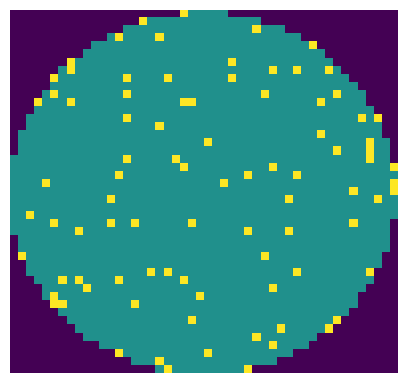

Total: 811457
Labeled: 172950
failureType_clean
none         147431
Edge-Ring      9680
Edge-Loc       5189
Center         4294
Loc            3593
Scratch        1193
Random          866
Donut           555
Near-full       149
Name: count, dtype: int64


In [ ]:
# ============================================================
# DAY 1
# Dataset Inspection / Label Cleaning
# ============================================================

PKL_PATH = (
    RAW_DIR / "LSWMD.pkl"
)

print(
    "Exists:",
    PKL_PATH.exists()
)

df = pd.read_pickle(
    PKL_PATH
)

print(
    "Shape:",
    df.shape
)

print(
    "Columns:",
    df.columns.tolist()
)

display(
    df.head()
)


# ------------------------------------------------------------
# waferMap 확인
# ------------------------------------------------------------

sample_wafer = (
    df.iloc[0]["waferMap"]
)

print(
    "Shape:",
    sample_wafer.shape
)

print(
    "Values:",
    np.unique(sample_wafer)
)

plt.figure(
    figsize=(5, 5)
)

plt.imshow(
    sample_wafer,
    interpolation="nearest"
)

plt.axis("off")
plt.show()


# ------------------------------------------------------------
# failureType cleaning
# ------------------------------------------------------------

def unwrap_label(x):

    if isinstance(
        x,
        np.ndarray
    ):

        if x.size == 0:
            return None

        x = (
            x.reshape(-1)[0]
        )

    if pd.isna(x):
        return None

    x = str(x).strip()

    if x == "":
        return None

    return x


df[
    "failureType_clean"
] = (
    df["failureType"]
    .apply(unwrap_label)
)


# ------------------------------------------------------------
# Labeled data
# ------------------------------------------------------------

labeled_df = df[
    df[
        "failureType_clean"
    ].notna()
].copy()

print(
    "Total:",
    len(df)
)

print(
    "Labeled:",
    len(labeled_df)
)

print(
    labeled_df[
        "failureType_clean"
    ].value_counts()
)


# ------------------------------------------------------------
# Save
# ------------------------------------------------------------

labeled_df.to_pickle(
    PROCESSED_DIR /
    "wm811k_labeled.pkl"
)


# ============================================================
# DAY 1 SUMMARY
#
# Total wafers   : 811,457
# Labeled wafers : 172,950
# Unlabeled      : 638,507
#
# 핵심:
# None  = label 없음
# "none" = 정상 wafer
# ============================================================

In [ ]:
# ============================================================
# DAY 1 SUMMARY
# WM-811K Dataset Loading / Structure Inspection / Label Cleaning
# ============================================================

# ------------------------------------------------------------
# 1. DAY 1 목표
# ------------------------------------------------------------
#
# 프로젝트 첫 단계에서는 바로 CNN을 학습하지 않고,
# WM-811K 데이터셋의 실제 구조를 먼저 확인하였다.
#
# 주요 목적:
#
# 1) LSWMD.pkl 파일이 정상적으로 로딩되는지 확인
# 2) DataFrame의 컬럼 구조 확인
# 3) waferMap이 어떤 형태의 데이터인지 확인
# 4) failureType이 어떤 자료형으로 저장되어 있는지 확인
# 5) lotName 구조 확인
# 6) label이 없는 wafer와 정상 wafer를 구분
#
# 모델 성능보다 데이터 구조를 정확히 이해하는 것이
# 이후 실험의 신뢰성을 결정한다고 판단하였다.
#
#
# ------------------------------------------------------------
# 2. Dataset Loading
# ------------------------------------------------------------
#
# 사용 파일:
#
#   LSWMD.pkl
#
# 로딩 후 확인된 전체 데이터 크기:
#
#   Total wafers = 811,457
#
# 확인된 주요 컬럼:
#
#   waferMap
#   dieSize
#   lotName
#   waferIndex
#   trianTestLabel
#   failureType
#
# 주의:
#
# 원본 파일에서는
#
#   trainTestLabel
#
# 이 아니라
#
#   trianTestLabel
#
# 로 저장되어 있었다.
#
# 따라서 이후 코드에서도 실제 컬럼명을 그대로 사용하였다.
#
#
# ------------------------------------------------------------
# 3. waferMap 구조 확인
# ------------------------------------------------------------
#
# waferMap은 일반 JPEG/PNG 이미지가 아니라
# 2차원 numpy array 형태의 wafer grid 데이터였다.
#
# 첫 sample 예:
#
#   shape = (45, 48)
#
# 주요 값:
#
#   0 = wafer background
#   1 = normal die
#   2 = defect die
#
# 따라서 waferMap은 일반 자연 이미지보다
# 범주형 spatial grid에 가깝다고 판단하였다.
#
# 이 점은 이후 interpolation 방식 결정에 중요하게 작용한다.
#
#
# ------------------------------------------------------------
# 4. failureType 구조 확인
# ------------------------------------------------------------
#
# failureType은 단순 문자열이 아니라
# numpy.ndarray 형태로 저장되어 있었다.
#
# 예:
#
#   array([['none']])
#
# 따라서 다음과 같은 문자열 정제 과정이 필요했다.
#
#   ndarray
#      ↓
#   flatten
#      ↓
#   string extraction
#      ↓
#   strip
#      ↓
#   clean label
#
#
# ------------------------------------------------------------
# 5. 가장 중요한 Label 구분
# ------------------------------------------------------------
#
# 데이터 확인 과정에서 다음 두 값이
# 완전히 다른 의미임을 확인하였다.
#
#
#   None
#
#   → failureType 자체가 없는 wafer
#   → unlabeled data
#
#
#   "none"
#
#   → 정상 wafer
#   → 실제 classification class
#
#
# 따라서:
#
#   None != "none"
#
# 이라는 원칙을 유지하였다.
#
# 이를 구분하지 않으면
# unlabeled wafer가 normal class로 잘못 포함될 수 있다.
#
#
# ------------------------------------------------------------
# 6. Labeled Data 추출
# ------------------------------------------------------------
#
# 전체 wafer:
#
#   811,457
#
# 실제 failureType label이 존재하는 wafer:
#
#   172,950
#
# label이 없는 wafer:
#
#   638,507
#
# 이후 classification 학습에는
# 172,950개의 labeled wafer만 사용하기로 결정하였다.
#
#
# ------------------------------------------------------------
# 7. Production Lot 구조 확인
# ------------------------------------------------------------
#
# unique lotName:
#
#   46,293 lots
#
# lot당 wafer 수 통계:
#
#   mean   ≈ 17.63
#   median = 24
#   max    = 25
#
# 동일 lot에 여러 wafer가 포함되어 있다는 점을 확인하였다.
#
# 이 결과는 이후 train/test split에서 중요한 문제가 된다.
#
# 만약 wafer 단위 random split을 사용할 경우:
#
#   lot_A wafer_1 → Train
#   lot_A wafer_2 → Train
#   lot_A wafer_3 → Test
#
# 와 같이 같은 생산 lot의 wafer가
# 서로 다른 split에 포함될 가능성이 있다.
#
# 이 경우 동일한 생산 조건을 공유하는 wafer가
# Train과 Test에 동시에 존재하면서
# generalization performance가 실제보다 높게 측정될
# 가능성이 있다.
#
#
# ------------------------------------------------------------
# 8. DAY 1 핵심 결과
# ------------------------------------------------------------
#
# Total wafers:
#
#   811,457
#
# Labeled wafers:
#
#   172,950
#
# Unlabeled wafers:
#
#   638,507
#
# Unique lots:
#
#   46,293
#
#
# 핵심 데이터 처리 원칙:
#
#   None
#       = label 없음
#
#   "none"
#       = 정상 wafer class
#
#
# ------------------------------------------------------------
# 9. DAY 1 결론
# ------------------------------------------------------------
#
# Day 1에서는 모델 학습보다
# WM-811K 데이터 구조를 정확히 이해하는 데 집중하였다.
#
# 특히 failureType이 ndarray로 저장되어 있다는 점,
# label이 없는 wafer와 정상 wafer가 별도로 존재한다는 점,
# 동일 lot에 여러 wafer가 포함되어 있다는 점을 확인하였다.
#
# 이 세 가지는 이후
#
#   label cleaning
#   lot-aware split
#   class imbalance analysis
#
# 의 근거가 되었다.
#
#
# ------------------------------------------------------------
# 10. 다음 단계
# ------------------------------------------------------------
#
# Day 2에서는:
#
#   - 9개 class 실제 패턴 시각화
#   - wafer shape 분석
#   - resize vs padding 비교
#   - class distribution 확인
#
# 을 수행하여 CNN 입력 전처리 방식을 결정한다.
#
# ============================================================

              height          width
count  172950.000000  172950.000000
mean       35.232807      34.822128
std        11.096015      11.876781
min        15.000000       3.000000
25%        27.000000      27.000000
50%        33.000000      33.000000
75%        41.000000      40.000000
max       212.000000     204.000000


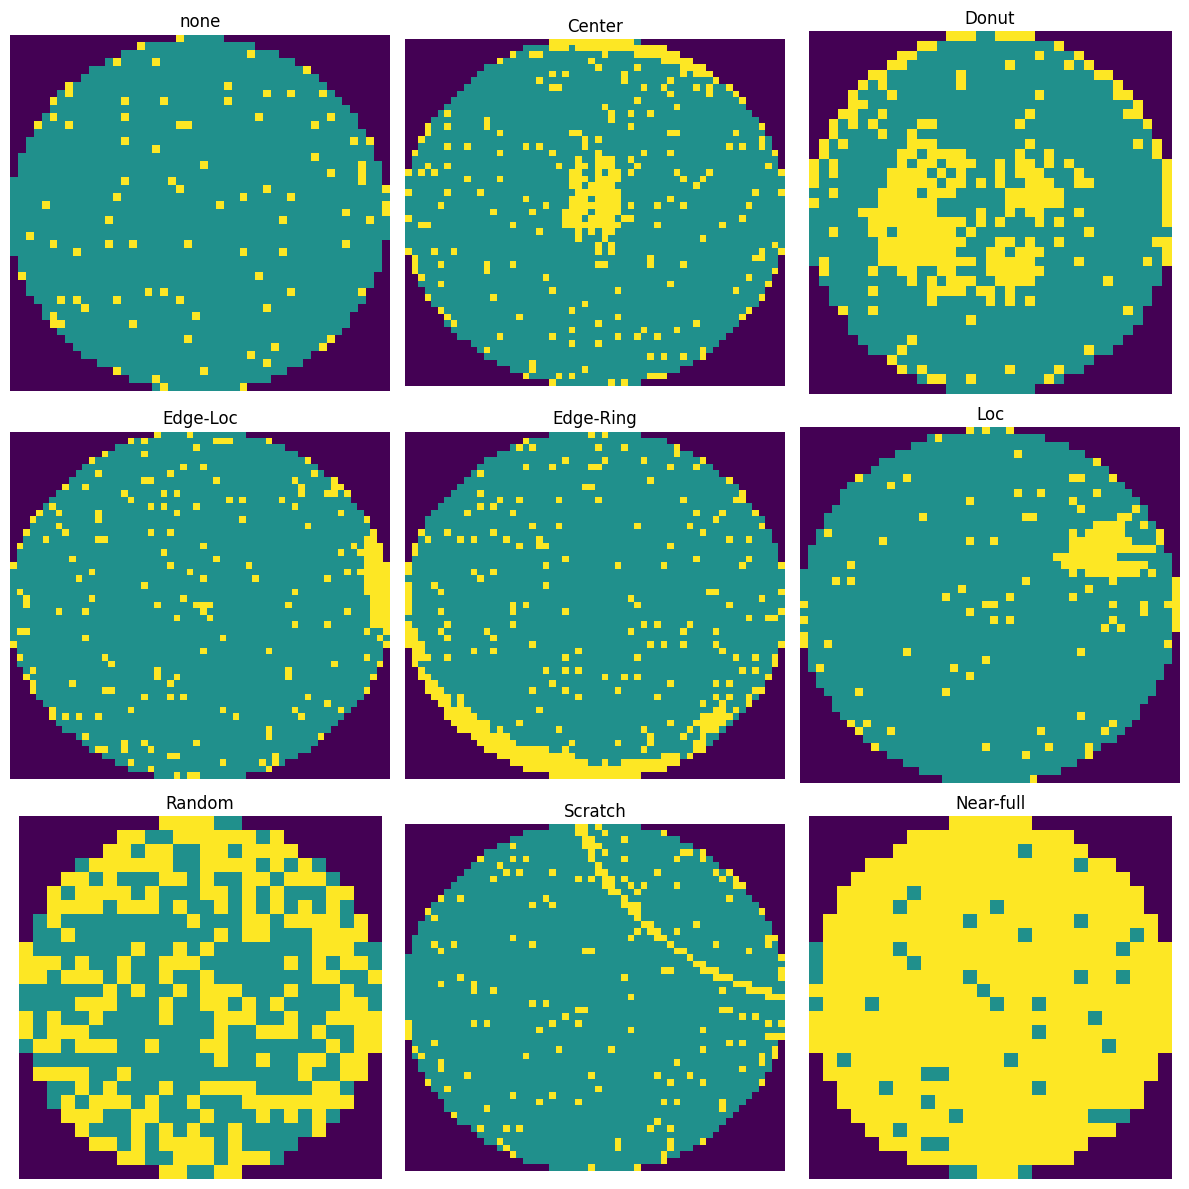

,count
failureType_clean,
none,147431
Edge-Ring,9680
Edge-Loc,5189
Center,4294
Loc,3593
Scratch,1193
Random,866
Donut,555
Near-full,149


Missing labels: 0


In [ ]:
# ============================================================
# DAY 2
# EDA / Preprocessing
# ============================================================

labeled_df = pd.read_pickle(
    PROCESSED_DIR /
    "wm811k_labeled.pkl"
)


# ------------------------------------------------------------
# Shape
# ------------------------------------------------------------

labeled_df["height"] = (
    labeled_df["waferMap"]
    .apply(
        lambda x:
        x.shape[0]
    )
)

labeled_df["width"] = (
    labeled_df["waferMap"]
    .apply(
        lambda x:
        x.shape[1]
    )
)

print(
    labeled_df[
        ["height", "width"]
    ].describe()
)


# ------------------------------------------------------------
# Class samples
# ------------------------------------------------------------

fig, axes = plt.subplots(
    3,
    3,
    figsize=(12, 12)
)

for ax, cls in zip(
    axes.flat,
    class_names
):

    row = labeled_df[
        labeled_df[
            "failureType_clean"
        ] == cls
    ].iloc[0]

    ax.imshow(
        row["waferMap"],
        interpolation="nearest"
    )

    ax.set_title(
        cls
    )

    ax.axis("off")

plt.tight_layout()
plt.show()


# ------------------------------------------------------------
# Class distribution
# ------------------------------------------------------------

class_counts = (
    labeled_df[
        "failureType_clean"
    ]
    .value_counts()
)

display(
    class_counts
)


# ------------------------------------------------------------
# Label encoding
# ------------------------------------------------------------

labeled_df[
    "label"
] = (
    labeled_df[
        "failureType_clean"
    ]
    .map(label_map)
)

print(
    "Missing labels:",
    labeled_df[
        "label"
    ].isna().sum()
)


# ------------------------------------------------------------
# Save
# ------------------------------------------------------------

labeled_df.to_pickle(
    PROCESSED_DIR /
    "wm811k_labeled_v2.pkl"
)


# ============================================================
# DAY 2 SUMMARY
#
# Input:
# 1 × 64 × 64
#
# Resize:
# INTER_NEAREST
#
# none class:
# 약 85.25%
#
# → severe class imbalance 확인
# ============================================================

In [ ]:
# ============================================================
# DAY 2 SUMMARY
# EDA / Wafer Shape Analysis / Preprocessing Decision
# ============================================================

# ------------------------------------------------------------
# 1. DAY 2 목표
# ------------------------------------------------------------
#
# Day 1에서 데이터 구조를 확인한 뒤,
# Day 2에서는 CNN 학습 전에 필요한
# 이미지 전처리 규칙을 결정하였다.
#
# 주요 질문:
#
# 1) 9개 defect class는 실제로 어떤 형태를 가지는가?
# 2) waferMap의 크기는 모두 동일한가?
# 3) CNN 입력 크기를 어떻게 통일할 것인가?
# 4) resize와 padding 중 어떤 방법이 적절한가?
# 5) class imbalance는 어느 정도인가?
#
#
# ------------------------------------------------------------
# 2. 9개 Class 확인
# ------------------------------------------------------------
#
# 사용 class:
#
#   0 = none
#   1 = Center
#   2 = Donut
#   3 = Edge-Loc
#   4 = Edge-Ring
#   5 = Loc
#   6 = Random
#   7 = Scratch
#   8 = Near-full
#
# 각 class의 waferMap sample을 직접 시각화하여
# spatial pattern을 확인하였다.
#
# 예:
#
#   Center
#   → 중앙 defect cluster
#
#   Edge-Ring
#   → wafer edge를 따라 ring 형태의 defect
#
#   Edge-Loc
#   → edge 주변의 특정 local defect
#
#   Scratch
#   → 선형 defect pattern
#
#   Donut
#   → ring / donut 형태
#
# 단,
# pattern 이름만으로 실제 공정 root cause를
# 확정할 수는 없다.
#
#
# ------------------------------------------------------------
# 3. Wafer Shape 분석
# ------------------------------------------------------------
#
# waferMap의 spatial size가 모두 동일하지 않음을 확인하였다.
#
# 예:
#
#   45 × 48
#   26 × 26
#   32 × 29
#   ...
#
# CNN batch input은 동일한 H × W 크기가 필요하므로
# input size normalization이 필요했다.
#
#
# ------------------------------------------------------------
# 4. Resize vs Padding 비교
# ------------------------------------------------------------
#
# 두 가지 방식을 비교하였다.
#
#
# Method A:
#
#   Direct resize
#
#   original
#      ↓
#   64 × 64
#
#
# Method B:
#
#   Aspect-ratio preserving resize
#            +
#          padding
#
#
# 단순히 이론적으로 결정하지 않고
# 실제 non-square wafer sample을 직접 시각화하였다.
#
# 이는 전처리 과정 자체가 spatial defect pattern을
# 왜곡할 가능성이 있기 때문이다.
#
#
# ------------------------------------------------------------
# 5. Nearest-Neighbor Interpolation 선택
# ------------------------------------------------------------
#
# waferMap은 일반 RGB 이미지가 아니라
# 0 / 1 / 2 값을 가진 categorical grid이다.
#
# 따라서 bilinear interpolation을 사용할 경우:
#
#   0
#   1
#   2
#
# 사이에 원래 존재하지 않는 중간값이 생성될 수 있다.
#
# 예:
#
#   1.25
#   1.5
#   ...
#
# 이러한 값은 실제 die 상태를 의미하지 않는다.
#
# 따라서:
#
#   cv2.INTER_NEAREST
#
# 를 사용하였다.
#
#
# ------------------------------------------------------------
# 6. Baseline Input Size 결정
# ------------------------------------------------------------
#
# 최종 baseline input:
#
#   64 × 64
#
# channel:
#
#   1 channel
#
# 최종 CNN input:
#
#   [1, 64, 64]
#
# pixel scaling:
#
#   0 → 0.0
#   1 → 0.5
#   2 → 1.0
#
#
# ------------------------------------------------------------
# 7. Class Distribution 분석
# ------------------------------------------------------------
#
# labeled data 기준 class count:
#
#   none       : 147,431
#   Edge-Ring  : 9,680
#   Edge-Loc   : 5,189
#   Center     : 4,294
#   Loc        : 3,593
#   Scratch    : 1,193
#   Random     : 866
#   Donut      : 555
#   Near-full  : 149
#
#
# normal class인 none:
#
#   약 85.25%
#
# 즉 데이터가 매우 심하게 imbalance되어 있었다.
#
#
# ------------------------------------------------------------
# 8. 중요한 평가 문제 발견
# ------------------------------------------------------------
#
# 만약 모든 sample을 단순히 none으로 예측해도
# Accuracy가 매우 높게 나올 가능성이 있다.
#
# 따라서 이후 모델 평가에서는
# Accuracy만 사용하지 않고 다음 지표를 함께 사용하기로 했다.
#
#   Accuracy
#   Balanced Accuracy
#   Macro-F1
#   Per-class Recall
#   Confusion Matrix
#
#
# ------------------------------------------------------------
# 9. Label Encoding
# ------------------------------------------------------------
#
# 문자열 label을 integer ID로 변환하였다.
#
#   none      → 0
#   Center    → 1
#   Donut     → 2
#   Edge-Loc  → 3
#   Edge-Ring → 4
#   Loc       → 5
#   Random    → 6
#   Scratch   → 7
#   Near-full → 8
#
# missing label:
#
#   0
#
# 인 것을 확인하였다.
#
#
# ------------------------------------------------------------
# 10. DAY 2 결론
# ------------------------------------------------------------
#
# 최종 preprocessing:
#
#   64 × 64
#   INTER_NEAREST
#   1 channel
#   value normalization = / 2.0
#
# 그리고 severe class imbalance를 확인하였다.
#
# 특히:
#
#   none ≈ 85%
#
# 라는 결과는 이후
#
#   baseline
#   class weight
#   augmentation
#
# 실험을 설계하게 된 중요한 이유가 된다.
#
#
# ------------------------------------------------------------
# 11. 다음 단계
# ------------------------------------------------------------
#
# Day 3에서는:
#
# 동일 생산 lot이 서로 다른 split에 들어가지 않도록
# lot-aware Train / Validation / Test split을 구성한다.
#
# ============================================================

In [ ]:
# ============================================================
# DAY 3
# Lot-aware Split / DataLoader
# ============================================================

labeled_df = pd.read_pickle(
    PROCESSED_DIR /
    "wm811k_labeled_v2.pkl"
)


# ------------------------------------------------------------
# Train / Temp
# ------------------------------------------------------------

gss1 = GroupShuffleSplit(
    n_splits=1,
    train_size=0.70,
    random_state=42
)

train_idx, temp_idx = next(
    gss1.split(
        labeled_df,
        groups=labeled_df[
            "lotName"
        ]
    )
)

train_df = (
    labeled_df
    .iloc[train_idx]
    .copy()
)

temp_df = (
    labeled_df
    .iloc[temp_idx]
    .copy()
)


# ------------------------------------------------------------
# Validation / Test
# ------------------------------------------------------------

gss2 = GroupShuffleSplit(
    n_splits=1,
    train_size=0.50,
    random_state=42
)

val_idx, test_idx = next(
    gss2.split(
        temp_df,
        groups=temp_df[
            "lotName"
        ]
    )
)

val_df = (
    temp_df
    .iloc[val_idx]
    .copy()
)

test_df = (
    temp_df
    .iloc[test_idx]
    .copy()
)


# ------------------------------------------------------------
# Leakage check
# ------------------------------------------------------------

train_lots = set(
    train_df["lotName"]
)

val_lots = set(
    val_df["lotName"]
)

test_lots = set(
    test_df["lotName"]
)

print(
    "Train ∩ Val :",
    len(
        train_lots
        &
        val_lots
    )
)

print(
    "Train ∩ Test:",
    len(
        train_lots
        &
        test_lots
    )
)

print(
    "Val ∩ Test  :",
    len(
        val_lots
        &
        test_lots
    )
)


# ------------------------------------------------------------
# Save split
# ------------------------------------------------------------

train_df.to_pickle(
    PROCESSED_DIR /
    "train_lot_split.pkl"
)

val_df.to_pickle(
    PROCESSED_DIR /
    "val_lot_split.pkl"
)

test_df.to_pickle(
    PROCESSED_DIR /
    "test_lot_split.pkl"
)


# ------------------------------------------------------------
# DataLoader
# ------------------------------------------------------------

train_dataset = WaferDataset(
    train_df
)

val_dataset = WaferDataset(
    val_df
)

test_dataset = WaferDataset(
    test_df
)

BATCH_SIZE = 128

train_loader = DataLoader(
    train_dataset,
    batch_size=BATCH_SIZE,
    shuffle=True,
    num_workers=2,
    pin_memory=True
)

val_loader = DataLoader(
    val_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=2,
    pin_memory=True
)

test_loader = DataLoader(
    test_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=2,
    pin_memory=True
)


# ============================================================
# DAY 3 SUMMARY
#
# Train : 120,979
# Val   : 26,116
# Test  : 25,855
#
# Lot overlap:
# 0 / 0 / 0
#
# Input batch:
# [128, 1, 64, 64]
# ============================================================

Type: <class 'pandas.core.frame.DataFrame'>
Shape: (811457, 6)


In [ ]:
# ============================================================
# DAY 3 SUMMARY
# Lot-Aware Split / Leakage Prevention / PyTorch Pipeline
# ============================================================

# ------------------------------------------------------------
# 1. DAY 3 목표
# ------------------------------------------------------------
#
# Day 1에서 동일 lot에 여러 wafer가 존재한다는 것을
# 확인하였다.
#
# 따라서 Day 3의 핵심 목표는
#
#   "같은 lot이 Train / Validation / Test에
#    동시에 존재하지 않도록 분할"
#
# 하는 것이었다.
#
#
# ------------------------------------------------------------
# 2. Random Split 문제
# ------------------------------------------------------------
#
# wafer-level random split을 사용할 경우:
#
#   lot123 wafer_1 → Train
#   lot123 wafer_2 → Train
#   lot123 wafer_3 → Test
#
# 와 같은 상황이 발생할 수 있다.
#
# 동일 lot의 wafer는 유사한 공정 조건을 공유할 수 있기 때문에
# 이러한 split은 generalization performance를
# 실제보다 높게 평가할 가능성이 있다.
#
#
# ------------------------------------------------------------
# 3. GroupShuffleSplit 사용
# ------------------------------------------------------------
#
# lotName을 group으로 사용하여 split하였다.
#
# 목표:
#
#   Train      ≈ 70%
#   Validation ≈ 15%
#   Test       ≈ 15%
#
#
# 실제 결과:
#
#   Train      = 120,979
#   Validation = 26,116
#   Test       = 25,855
#
#
# 실제 비율:
#
#   Train      ≈ 69.95%
#   Validation ≈ 15.10%
#   Test       ≈ 14.95%
#
# lot 단위로 분리하기 때문에
# 정확히 70/15/15가 아니어도 정상이다.
#
#
# ------------------------------------------------------------
# 4. Leakage Check
# ------------------------------------------------------------
#
# 다음 세 조건을 직접 검사하였다.
#
#   Train ∩ Validation
#   Train ∩ Test
#   Validation ∩ Test
#
# 결과:
#
#   Train ∩ Val  = 0
#   Train ∩ Test = 0
#   Val ∩ Test   = 0
#
# 즉 동일한 생산 lot이
# 서로 다른 split에 동시에 존재하지 않음을 확인하였다.
#
#
# ------------------------------------------------------------
# 5. Split 이후 Class Distribution
# ------------------------------------------------------------
#
# Group split 이후에도
# class distribution이 심하게 무너지지 않았는지 확인하였다.
#
# 예:
#
#   none
#
#   Train ≈ 85.22%
#   Val   ≈ 85.25%
#   Test  ≈ 85.35%
#
# 즉 lot-aware split을 사용했음에도
# 전체적인 class distribution은 비교적 안정적으로 유지되었다.
#
#
# ------------------------------------------------------------
# 6. Rare Class 문제
# ------------------------------------------------------------
#
# Near-full class는 원래 전체 sample 수가 매우 적다.
#
# Test support:
#
#   15
#
# 따라서 Near-full recall은
# sample 한두 개만 바뀌어도 크게 변한다.
#
# 이 class의 성능은
# 통계적으로 불안정할 수 있으므로
# 최종 결과에서 과도하게 해석하지 않기로 했다.
#
#
# ------------------------------------------------------------
# 7. PyTorch Dataset 구성
# ------------------------------------------------------------
#
# preprocessing pipeline:
#
#   waferMap
#       ↓
#   64×64 nearest resize
#       ↓
#   float32
#       ↓
#   / 2.0
#       ↓
#   [64,64]
#       ↓
#   unsqueeze
#       ↓
#   [1,64,64]
#
#
# ------------------------------------------------------------
# 8. DataLoader 구성
# ------------------------------------------------------------
#
# Batch size:
#
#   128
#
# Train:
#
#   shuffle=True
#
# Validation/Test:
#
#   shuffle=False
#
#
# 최종 batch shape:
#
#   [128, 1, 64, 64]
#
#
# ------------------------------------------------------------
# 9. DAY 3 핵심 결과
# ------------------------------------------------------------
#
# Train:
#
#   120,979
#
# Validation:
#
#   26,116
#
# Test:
#
#   25,855
#
#
# Lot overlap:
#
#   0 / 0 / 0
#
#
# ------------------------------------------------------------
# 10. DAY 3 결론
# ------------------------------------------------------------
#
# 본 프로젝트에서는 단순 random split 대신
# lot-aware split을 사용하였다.
#
# 이를 통해 동일 생산 lot이
# Train/Test에 동시에 들어가는 것을 방지하였다.
#
# 이후 모든 실험:
#
#   Baseline
#   Weighted
#   Tempered
#   Augmentation
#
# 은 동일한 split을 사용한다.
#
# 이를 통해 모델 간 비교 조건을 고정하였다.
#
#
# ------------------------------------------------------------
# 11. 다음 단계
# ------------------------------------------------------------
#
# Day 4에서는 class imbalance 처리를 전혀 하지 않은
# Simple CNN baseline을 학습한다.
#
# 목적:
#
#   이후 class weighting 등의 개선 효과를
#   비교할 기준점 확보
#
# ============================================================

In [ ]:
# ============================================================
# DAY 4
# Baseline CNN
# ============================================================

baseline_model = SimpleCNN(
    num_classes=9
).to(device)

baseline_criterion = (
    nn.CrossEntropyLoss()
)

baseline_optimizer = (
    torch.optim.Adam(
        baseline_model.parameters(),
        lr=1e-3
    )
)

BASELINE_PATH = (
    MODEL_DIR /
    "baseline_cnn_best.pt"
)

baseline_history, baseline_best_f1 = (
    run_training(
        baseline_model,
        train_loader,
        val_loader,
        baseline_criterion,
        baseline_optimizer,
        BASELINE_PATH,
        epochs=10
    )
)

baseline_result = test_model(
    baseline_model,
    BASELINE_PATH,
    test_loader,
    baseline_criterion
)

print(
    baseline_result
)


# ============================================================
# DAY 4 RESULT
#
# Accuracy:
# 0.9663
#
# Balanced Accuracy:
# 0.7851
#
# Macro-F1:
# 0.7745
#
# Scratch Recall:
# 0.0395
# ============================================================

Epoch 01/10 | Train Loss 0.2572 | Train Acc 0.9354 | Val Loss 0.3138 | Val Acc 0.9173 | Macro-F1 0.6077 | Balanced Acc 0.6997
 → Best model saved
Epoch 02/10 | Train Loss 0.1483 | Train Acc 0.9557 | Val Loss 0.1962 | Val Acc 0.9532 | Macro-F1 0.6912 | Balanced Acc 0.6830
 → Best model saved
Epoch 03/10 | Train Loss 0.1255 | Train Acc 0.9617 | Val Loss 0.1111 | Val Acc 0.9640 | Macro-F1 0.7060 | Balanced Acc 0.7440
 → Best model saved
Epoch 04/10 | Train Loss 0.1137 | Train Acc 0.9643 | Val Loss 0.1849 | Val Acc 0.9586 | Macro-F1 0.7215 | Balanced Acc 0.6638
 → Best model saved
Epoch 05/10 | Train Loss 0.1013 | Train Acc 0.9673 | Val Loss 0.1046 | Val Acc 0.9671 | Macro-F1 0.7831 | Balanced Acc 0.7827
 → Best model saved
Epoch 06/10 | Train Loss 0.0950 | Train Acc 0.9682 | Val Loss 0.3170 | Val Acc 0.9497 | Macro-F1 0.6770 | Balanced Acc 0.5986
Epoch 07/10 | Train Loss 0.0865 | Train Acc 0.9711 | Val Loss 0.1147 | Val Acc 0.9633 | Macro-F1 0.7632 | Balanced Acc 0.7525
Epoch 08/10 | Trai

In [ ]:
# ============================================================
# DAY 4 SUMMARY
# Baseline CNN / Initial Performance / Minority Failure Discovery
# ============================================================

# ------------------------------------------------------------
# 1. DAY 4 목표
# ------------------------------------------------------------
#
# Day 4에서는 class imbalance 처리를 적용하지 않은
# Simple CNN baseline을 구축하였다.
#
# 목적:
#
#   "아무 imbalance 대응을 하지 않았을 때
#    모델이 실제로 어떤 성능을 보이는가?"
#
# 를 확인하고,
# 이후 weighted model과 비교할 기준점을 확보하는 것.
#
#
# ------------------------------------------------------------
# 2. Model Architecture
# ------------------------------------------------------------
#
# CNN 구조:
#
#   Conv2d
#   BatchNorm
#   ReLU
#   MaxPool
#
#   Conv2d
#   BatchNorm
#   ReLU
#   MaxPool
#
#   Conv2d
#   BatchNorm
#   ReLU
#   MaxPool
#
#   Flatten
#
#   Linear
#   ReLU
#   Dropout
#   Linear
#
#
# input:
#
#   [1, 64, 64]
#
# output:
#
#   9 classes
#
#
# ------------------------------------------------------------
# 3. Training Setup
# ------------------------------------------------------------
#
# Loss:
#
#   CrossEntropyLoss
#
# class weight:
#
#   None
#
# Optimizer:
#
#   Adam
#
# Learning Rate:
#
#   1e-3
#
# Batch Size:
#
#   128
#
# Epochs:
#
#   10
#
#
# ------------------------------------------------------------
# 4. Best Model 기준
# ------------------------------------------------------------
#
# dataset이 매우 imbalance되어 있기 때문에
# Accuracy를 best model selection 기준으로 사용하지 않았다.
#
# 대신:
#
#   Validation Macro-F1
#
# 이 가장 높은 epoch의 model을 저장하였다.
#
# 이유:
#
# Macro-F1은 각 class를 동일한 비중으로 평가하므로
# majority class인 none에만 좋은 모델을
# 과도하게 높게 평가하는 문제를 줄일 수 있다.
#
#
# ------------------------------------------------------------
# 5. Training 결과
# ------------------------------------------------------------
#
# Best Validation Macro-F1:
#
#   Epoch 7
#
# 해당 epoch:
#
#   Val Accuracy          ≈ 0.9642
#   Val Macro-F1          ≈ 0.7620
#   Val Balanced Accuracy ≈ 0.7649
#
#
# 학습 과정에서:
#
#   Train Loss 감소
#   Train Accuracy 증가
#
# 를 확인하여 model 자체는 정상적으로 학습되었다.
#
#
# ------------------------------------------------------------
# 6. Test Result
# ------------------------------------------------------------
#
# Accuracy:
#
#   0.9663
#
# Balanced Accuracy:
#
#   0.7851
#
# Macro-F1:
#
#   0.7745
#
# Weighted F1:
#
#   0.9632
#
#
# ------------------------------------------------------------
# 7. Class-wise Recall
# ------------------------------------------------------------
#
# none:
#
#   0.9881
#
# Center:
#
#   0.9602
#
# Donut:
#
#   0.8675
#
# Edge-Loc:
#
#   0.8290
#
# Edge-Ring:
#
#   0.9832
#
# Loc:
#
#   0.5851
#
# Random:
#
#   0.9466
#
# Scratch:
#
#   0.0395
#
# Near-full:
#
#   0.8667
#
#
# ------------------------------------------------------------
# 8. 가장 중요한 발견
# ------------------------------------------------------------
#
# 전체 Accuracy:
#
#   96.63%
#
# 로 매우 높았지만,
#
# Scratch Recall:
#
#   3.95%
#
# 에 불과했다.
#
#
# 즉:
#
#   High Accuracy
#       !=
#   Good performance for every class
#
#
# 임을 실제 결과로 확인하였다.
#
#
# ------------------------------------------------------------
# 9. Scratch 문제
# ------------------------------------------------------------
#
# Scratch class는 minority class이며
# baseline에서 거의 대부분을 놓치고 있었다.
#
# Recall:
#
#   0.0395
#
# 즉 Scratch sample 중 약 96%를
# 다른 class로 예측하고 있었다.
#
#
# ------------------------------------------------------------
# 10. Loc 문제
# ------------------------------------------------------------
#
# Loc Recall:
#
#   0.5851
#
# 역시 상대적으로 낮았다.
#
# 따라서 모델이 일부 local defect pattern을
# 안정적으로 구분하지 못하고 있음을 확인하였다.
#
#
# ------------------------------------------------------------
# 11. DAY 4 결론
# ------------------------------------------------------------
#
# Baseline CNN은:
#
#   Accuracy  = 96.63%
#   Macro-F1  = 0.7745
#
# 를 기록하였다.
#
# 그러나:
#
#   Scratch Recall = 3.95%
#   Loc Recall     = 58.51%
#
# 로 minority class 성능이 낮았다.
#
# 이는 class imbalance가 실제 prediction behavior에
# 영향을 주고 있음을 보여준다.
#
#
# ------------------------------------------------------------
# 12. 다음 단계
# ------------------------------------------------------------
#
# Day 5에서는 minority class를 더 강하게 학습시키기 위해
# class-weighted CrossEntropyLoss를 적용한다.
#
# 핵심 질문:
#
#   "minority class를 틀렸을 때 더 큰 penalty를 주면
#    Scratch / Loc Recall이 개선되는가?"
#
# ============================================================

In [ ]:
# ============================================================
# DAY 5
# Full Class Weight
# ============================================================

classes = np.arange(9)

class_weights_np = (
    compute_class_weight(
        class_weight="balanced",
        classes=classes,
        y=train_df[
            "label"
        ].values
    )
)

class_weights = torch.tensor(
    class_weights_np,
    dtype=torch.float32
).to(device)


weighted_model = SimpleCNN(
    num_classes=9
).to(device)

weighted_criterion = (
    nn.CrossEntropyLoss(
        weight=class_weights
    )
)

weighted_optimizer = (
    torch.optim.Adam(
        weighted_model.parameters(),
        lr=1e-3
    )
)

WEIGHTED_PATH = (
    MODEL_DIR /
    "weighted_cnn_best.pt"
)

weighted_history, weighted_best_f1 = (
    run_training(
        weighted_model,
        train_loader,
        val_loader,
        weighted_criterion,
        weighted_optimizer,
        WEIGHTED_PATH,
        epochs=10
    )
)

weighted_result = test_model(
    weighted_model,
    WEIGHTED_PATH,
    test_loader,
    weighted_criterion
)


# ============================================================
# DAY 5 RESULT
#
# Accuracy:
# 0.9330
#
# Balanced Accuracy:
# 0.8356
#
# Macro-F1:
# 0.7534
#
# Scratch Recall:
# 0.3446
# ============================================================

Epoch 01/10 | Train Loss 1.2031 | Train Acc 0.5293 | Val Loss 1.1009 | Val Acc 0.6896 | Macro-F1 0.4921 | Balanced Acc 0.6629
 → Best model saved
Epoch 02/10 | Train Loss 0.8986 | Train Acc 0.6664 | Val Loss 1.0081 | Val Acc 0.3619 | Macro-F1 0.5422 | Balanced Acc 0.7309
 → Best model saved
Epoch 03/10 | Train Loss 0.7826 | Train Acc 0.6901 | Val Loss 0.9534 | Val Acc 0.7776 | Macro-F1 0.4946 | Balanced Acc 0.7187
Epoch 04/10 | Train Loss 0.7067 | Train Acc 0.7273 | Val Loss 0.8300 | Val Acc 0.9178 | Macro-F1 0.6657 | Balanced Acc 0.7693
 → Best model saved
Epoch 05/10 | Train Loss 0.6483 | Train Acc 0.7425 | Val Loss 1.0692 | Val Acc 0.9494 | Macro-F1 0.7179 | Balanced Acc 0.7326
 → Best model saved
Epoch 06/10 | Train Loss 0.5997 | Train Acc 0.7665 | Val Loss 0.7395 | Val Acc 0.6843 | Macro-F1 0.6268 | Balanced Acc 0.8129
Epoch 07/10 | Train Loss 0.5622 | Train Acc 0.7687 | Val Loss 0.8238 | Val Acc 0.6954 | Macro-F1 0.5852 | Balanced Acc 0.7727
Epoch 08/10 | Train Loss 0.5381 | Trai

In [ ]:
# ============================================================
# DAY 5 SUMMARY
# Full Balanced Class Weight Experiment
# ============================================================

# ------------------------------------------------------------
# 1. DAY 5 목표
# ------------------------------------------------------------
#
# Baseline CNN에서 확인된 핵심 문제:
#
#   Scratch Recall = 3.95%
#
# 따라서 class imbalance가
# minority defect detection 성능을 제한하고 있을 가능성을
# 검증하기 위해 balanced class weight를 적용하였다.
#
#
# ------------------------------------------------------------
# 2. Weight 계산 원칙
# ------------------------------------------------------------
#
# class weight는 반드시 Train set만 사용하여 계산하였다.
#
# Validation/Test distribution을 이용하여 weight를 결정하면
# evaluation data 정보가 학습 설계에 포함될 수 있기 때문이다.
#
#
# ------------------------------------------------------------
# 3. Balanced Class Weights
# ------------------------------------------------------------
#
# Train 기준 계산 결과:
#
#   none       = 0.1304
#   Center     = 4.4688
#   Donut      = 36.7271
#   Edge-Loc   = 3.7031
#   Edge-Ring  = 1.9564
#   Loc        = 5.5753
#   Random     = 21.8927
#   Scratch    = 15.4330
#   Near-full  = 125.6272
#
#
# 특히:
#
#   Near-full = 125.6
#
# 로 매우 큰 weight가 계산되었다.
#
# 반면:
#
#   none = 0.13
#
# 로 매우 작았다.
#
#
# ------------------------------------------------------------
# 4. 실험 조건 통제
# ------------------------------------------------------------
#
# Baseline과 비교하기 위해 다음 조건을 동일하게 유지하였다.
#
#   CNN architecture
#   Input size
#   Batch size
#   Optimizer
#   Learning rate
#   Epochs
#   Train/Val/Test split
#
# 변경한 것은 Loss의 class weight뿐이다.
#
#
# ------------------------------------------------------------
# 5. Training Behavior
# ------------------------------------------------------------
#
# Weighted model은 baseline과 달리
# 초반 Accuracy가 매우 낮게 시작하였다.
#
# 이는 정상 class인 none의 영향력이 감소하고,
# minority class에 훨씬 큰 penalty가 부여되었기 때문이다.
#
#
# Epoch별 Validation 성능도 baseline보다 크게 흔들렸다.
#
# 예:
#
#   Epoch 8
#   Val Accuracy ≈ 94.95%
#
#   Epoch 10
#   Val Accuracy ≈ 33.31%
#
#
# 이 결과는 매우 큰 weight가
# gradient와 학습 안정성에 영향을 줄 가능성을 시사한다.
#
#
# ------------------------------------------------------------
# 6. Test Result
# ------------------------------------------------------------
#
# Accuracy:
#
#   0.9330
#
# Balanced Accuracy:
#
#   0.8356
#
# Macro-F1:
#
#   0.7534
#
#
# ------------------------------------------------------------
# 7. Baseline vs Weighted
# ------------------------------------------------------------
#
# Accuracy:
#
#   0.9663
#      ↓
#   0.9330
#
#
# Balanced Accuracy:
#
#   0.7851
#      ↑
#   0.8356
#
#
# Macro-F1:
#
#   0.7745
#      ↓
#   0.7534
#
#
# ------------------------------------------------------------
# 8. Scratch 개선
# ------------------------------------------------------------
#
# Scratch Recall:
#
#   Baseline
#   0.0395
#
#      ↓
#
#   Full Weighted
#   0.3446
#
#
# 즉:
#
#   3.95%
#      →
#   34.46%
#
#
# 약 30.5%p 개선되었다.
#
#
# ------------------------------------------------------------
# 9. 다른 Minority Class 변화
# ------------------------------------------------------------
#
# Donut:
#
#   0.8675 → 0.9759
#
# Edge-Loc:
#
#   0.8290 → 0.8536
#
# Near-full:
#
#   0.8667 → 0.9333
#
#
# 반면 none:
#
#   0.9881 → 0.9463
#
# 로 감소하였다.
#
#
# ------------------------------------------------------------
# 10. Balanced Accuracy vs Macro-F1
# ------------------------------------------------------------
#
# Balanced Accuracy는 증가했지만
# Macro-F1은 감소하였다.
#
# Balanced Accuracy:
#
#   각 class Recall을 동일 비중으로 평가
#
# Macro-F1:
#
#   Precision과 Recall을 모두 반영
#
#
# 즉 weighted model은
# minority class를 더 적극적으로 예측하면서
# Recall은 좋아졌지만,
# false positive가 증가했을 가능성이 있다.
#
#
# ------------------------------------------------------------
# 11. DAY 5 핵심 해석
# ------------------------------------------------------------
#
# Full class weighting은 분명히 효과가 있었다.
#
# 특히:
#
#   Scratch Recall
#   3.95% → 34.46%
#
# 로 매우 크게 개선되었다.
#
# 그러나:
#
#   Accuracy 감소
#   Macro-F1 감소
#   Training instability 증가
#
# 라는 trade-off가 발생하였다.
#
#
# ------------------------------------------------------------
# 12. DAY 5 결론
# ------------------------------------------------------------
#
# balanced class weight를 그대로 적용하면
# minority class detection에는 도움이 되지만
# 일부 weight가 지나치게 커져
# 전체 classification balance를 해칠 수 있음을 확인하였다.
#
# 특히:
#
#   Near-full weight = 125.6
#
# 는 매우 공격적인 weighting이었다.
#
#
# ------------------------------------------------------------
# 13. 다음 단계
# ------------------------------------------------------------
#
# Day 6에서는 weight 자체를 제거하지 않고
# rare class의 중요성은 유지하되
# 극단적인 weight만 완화한다.
#
# 방법:
#
#   tempered_weight
#       =
#   sqrt(class_weight)
#
# 핵심 질문:
#
#   "minority recall 개선은 어느 정도 유지하면서
#    Accuracy와 Macro-F1 손실을 줄일 수 있는가?"
#
# ============================================================

In [ ]:
# ============================================================
# DAY 6
# sqrt Class Weight
# ============================================================

sqrt_class_weights = (
    torch.sqrt(
        class_weights
    )
)

tempered_model = SimpleCNN(
    num_classes=9
).to(device)

tempered_criterion = (
    nn.CrossEntropyLoss(
        weight=
        sqrt_class_weights
    )
)

tempered_optimizer = (
    torch.optim.Adam(
        tempered_model.parameters(),
        lr=1e-3
    )
)

TEMPERED_PATH = (
    MODEL_DIR /
    "tempered_cnn_best.pt"
)

tempered_history, tempered_best_f1 = (
    run_training(
        tempered_model,
        train_loader,
        val_loader,
        tempered_criterion,
        tempered_optimizer,
        TEMPERED_PATH,
        epochs=10
    )
)

tempered_result = test_model(
    tempered_model,
    TEMPERED_PATH,
    test_loader,
    tempered_criterion
)


# ============================================================
# DAY 6 RESULT
#
# Accuracy:
# 0.9670
#
# Balanced Accuracy:
# 0.7748
#
# Macro-F1:
# 0.7861
#
# 대표 모델로 선택
# ============================================================

Epoch 01/10 | Train Loss 0.7396 | Train Acc 0.9078 | Val Loss 0.6821 | Val Acc 0.9455 | Macro-F1 0.6167 | Balanced Acc 0.5960
 → Best model saved
Epoch 02/10 | Train Loss 0.4814 | Train Acc 0.9305 | Val Loss 0.3594 | Val Acc 0.9526 | Macro-F1 0.7200 | Balanced Acc 0.7527
 → Best model saved
Epoch 03/10 | Train Loss 0.4201 | Train Acc 0.9393 | Val Loss 0.4048 | Val Acc 0.9561 | Macro-F1 0.7240 | Balanced Acc 0.7449
 → Best model saved
Epoch 04/10 | Train Loss 0.3763 | Train Acc 0.9428 | Val Loss 0.3217 | Val Acc 0.9532 | Macro-F1 0.7488 | Balanced Acc 0.8038
 → Best model saved
Epoch 05/10 | Train Loss 0.3422 | Train Acc 0.9444 | Val Loss 0.3342 | Val Acc 0.9482 | Macro-F1 0.7243 | Balanced Acc 0.7776
Epoch 06/10 | Train Loss 0.3216 | Train Acc 0.9469 | Val Loss 0.4435 | Val Acc 0.9641 | Macro-F1 0.7682 | Balanced Acc 0.7764
 → Best model saved
Epoch 07/10 | Train Loss 0.3004 | Train Acc 0.9473 | Val Loss 0.5451 | Val Acc 0.9636 | Macro-F1 0.7867 | Balanced Acc 0.7766
 → Best model save

In [ ]:
# ============================================================
# DAY 6 SUMMARY
# Tempered Class Weight / Trade-off Optimization
# ============================================================

# ------------------------------------------------------------
# 1. DAY 6 목표
# ------------------------------------------------------------
#
# Day 5 Full Weighted 실험에서는
# minority Recall은 크게 개선되었지만
# Accuracy와 Macro-F1이 감소하였다.
#
# 따라서 Day 6에서는
# extreme weight를 완화한 weighting strategy를 실험하였다.
#
#
# ------------------------------------------------------------
# 2. Tempered Weight 아이디어
# ------------------------------------------------------------
#
# 기존:
#
#   class_weight
#
# 에 square root를 적용하였다.
#
#   tempered_weight
#       =
#   sqrt(class_weight)
#
#
# 예:
#
#   Near-full
#
#   125.63
#      ↓
#   sqrt
#      ↓
#   약 11.21
#
#
# minority class를 더 중요하게 보되
# gradient impact가 지나치게 커지는 문제를 줄이는 것이 목적이었다.
#
#
# ------------------------------------------------------------
# 3. 실험 조건
# ------------------------------------------------------------
#
# 다음 조건은 Baseline / Full Weighted와 동일:
#
#   CNN architecture
#   Train/Val/Test split
#   Input size
#   Batch size
#   Optimizer
#   Learning rate
#   Epochs
#
# 변경:
#
#   Full balanced weight
#       ↓
#   sqrt weight
#
#
# ------------------------------------------------------------
# 4. Test Result
# ------------------------------------------------------------
#
# Accuracy:
#
#   0.9670
#
# Balanced Accuracy:
#
#   0.7748
#
# Macro-F1:
#
#   0.7861
#
#
# ------------------------------------------------------------
# 5. 세 모델 비교
# ------------------------------------------------------------
#
# Baseline:
#
#   Accuracy          = 0.9663
#   Balanced Accuracy = 0.7851
#   Macro-F1          = 0.7745
#
#
# Full Weighted:
#
#   Accuracy          = 0.9330
#   Balanced Accuracy = 0.8356
#   Macro-F1          = 0.7534
#
#
# Tempered:
#
#   Accuracy          = 0.9670
#   Balanced Accuracy = 0.7748
#   Macro-F1          = 0.7861
#
#
# ------------------------------------------------------------
# 6. Scratch 변화
# ------------------------------------------------------------
#
# Scratch Recall:
#
#   Baseline
#   0.0395
#
#   Full Weighted
#   0.3446
#
#   Tempered
#   0.1977
#
#
# Tempered model은 Full Weighted보다는 낮지만
# Baseline보다 Scratch detection 성능이 크게 개선되었다.
#
#
# ------------------------------------------------------------
# 7. Loc 변화
# ------------------------------------------------------------
#
# Loc Recall:
#
#   Baseline
#   0.5851
#
#      ↓
#
#   Tempered
#   0.6649
#
#
# 즉 Loc class에서도 improvement가 있었다.
#
#
# ------------------------------------------------------------
# 8. 개선되지 않은 Class
# ------------------------------------------------------------
#
# 모든 class가 좋아진 것은 아니다.
#
# Center:
#
#   0.9602 → 0.9104
#
# Edge-Loc:
#
#   0.8290 → 0.7850
#
# Random:
#
#   0.9466 → 0.9084
#
#
# 따라서:
#
#   Tempered CNN이 모든 class에서 우수하다
#
# 라고 결론 내리지는 않는다.
#
#
# ------------------------------------------------------------
# 9. Near-full 주의
# ------------------------------------------------------------
#
# Near-full Test support:
#
#   15
#
# Recall 변화:
#
#   0.8667 → 0.6667
#
# 하지만 sample 수가 매우 적으므로
# few samples만 달라져도 metric이 크게 변한다.
#
# 따라서 Near-full 결과는
# 강하게 해석하지 않는다.
#
#
# ------------------------------------------------------------
# 10. DAY 6 핵심 결과
# ------------------------------------------------------------
#
# Tempered CNN은:
#
#   Accuracy = 96.70%
#
# 으로 세 모델 중 가장 높았으며,
#
#   Macro-F1 = 0.7861
#
# 역시 가장 높았다.
#
#
# 동시에:
#
#   Scratch
#   Loc
#
# 같은 어려운 class의 Recall도
# Baseline보다 개선되었다.
#
#
# ------------------------------------------------------------
# 11. DAY 6 결론
# ------------------------------------------------------------
#
# Full weighting은 minority detection을
# 지나치게 공격적으로 개선하면서
# 전체 performance를 희생하였다.
#
# sqrt weighting을 적용한 Tempered model은
# weighting 강도를 완화하여
# 전체 Accuracy와 Macro-F1을 회복하면서
# 일부 minority class 개선 효과를 유지하였다.
#
#
# 현재 대표 모델:
#
#   Tempered CNN
#
#
# 선택 이유:
#
#   Highest Accuracy
#   Highest Macro-F1
#   Better Scratch Recall than baseline
#   Better Loc Recall than baseline
#
#
# ------------------------------------------------------------
# 12. 다음 단계
# ------------------------------------------------------------
#
# Day 7에서는 모델과 tempered weight를 그대로 유지하고
# augmentation만 추가한다.
#
# 핵심 질문:
#
#   "spatial augmentation이 minority class generalization을
#    추가로 개선할 수 있는가?"
#
# ============================================================

In [ ]:
# ============================================================
# DAY 7
# Tempered + Augmentation
# ============================================================

class AugmentedWaferDataset(
    WaferDataset
):

    def __init__(
        self,
        dataframe,
        target_size=64,
        augment=False
    ):

        super().__init__(
            dataframe,
            target_size
        )

        self.augment = augment

    def __getitem__(
        self,
        idx
    ):

        row = self.df.iloc[idx]

        wafer = resize_wafer(
            row["waferMap"],
            self.target_size
        )

        if self.augment:

            k = torch.randint(
                0,
                4,
                (1,)
            ).item()

            wafer = np.rot90(
                wafer,
                k
            )

            if (
                torch.rand(1).item()
                < 0.5
            ):
                wafer = np.fliplr(
                    wafer
                )

            if (
                torch.rand(1).item()
                < 0.5
            ):
                wafer = np.flipud(
                    wafer
                )

        wafer = (
            np.ascontiguousarray(
                wafer
            )
        )

        wafer = torch.tensor(
            wafer,
            dtype=torch.float32
        ) / 2.0

        wafer = wafer.unsqueeze(0)

        label = torch.tensor(
            int(row["label"]),
            dtype=torch.long
        )

        return wafer, label


aug_train_dataset = (
    AugmentedWaferDataset(
        train_df,
        augment=True
    )
)

aug_train_loader = DataLoader(
    aug_train_dataset,
    batch_size=128,
    shuffle=True,
    num_workers=2,
    pin_memory=True
)


augmented_model = SimpleCNN(
    num_classes=9
).to(device)

augmented_criterion = (
    nn.CrossEntropyLoss(
        weight=
        sqrt_class_weights
    )
)

augmented_optimizer = (
    torch.optim.Adam(
        augmented_model.parameters(),
        lr=1e-3
    )
)

AUG_PATH = (
    MODEL_DIR /
    "tempered_aug_cnn_best.pt"
)

aug_history, aug_best_f1 = (
    run_training(
        augmented_model,
        aug_train_loader,
        val_loader,
        augmented_criterion,
        augmented_optimizer,
        AUG_PATH,
        epochs=10
    )
)

aug_result = test_model(
    augmented_model,
    AUG_PATH,
    test_loader,
    augmented_criterion
)


# ============================================================
# DAY 7 RESULT
#
# Accuracy:
# 0.9660
#
# Balanced Accuracy:
# 0.8133
#
# Macro-F1:
# 0.7655
#
# Scratch Recall:
# 0.3333
# ============================================================

Epoch 01/10 | Train Loss 0.8071 | Train Acc 0.8988 | Val Loss 0.5300 | Val Acc 0.8999 | Macro-F1 0.5894 | Balanced Acc 0.7154
 → Best model saved
Epoch 02/10 | Train Loss 0.5690 | Train Acc 0.9189 | Val Loss 0.6264 | Val Acc 0.9527 | Macro-F1 0.6619 | Balanced Acc 0.6792
 → Best model saved
Epoch 03/10 | Train Loss 0.5260 | Train Acc 0.9213 | Val Loss 0.6257 | Val Acc 0.9446 | Macro-F1 0.6361 | Balanced Acc 0.6359
Epoch 04/10 | Train Loss 0.4766 | Train Acc 0.9289 | Val Loss 0.3586 | Val Acc 0.9353 | Macro-F1 0.6598 | Balanced Acc 0.7624
Epoch 05/10 | Train Loss 0.4576 | Train Acc 0.9292 | Val Loss 0.5721 | Val Acc 0.8077 | Macro-F1 0.6183 | Balanced Acc 0.7748
Epoch 06/10 | Train Loss 0.4355 | Train Acc 0.9333 | Val Loss 0.4140 | Val Acc 0.9043 | Macro-F1 0.6340 | Balanced Acc 0.7732
Epoch 07/10 | Train Loss 0.4115 | Train Acc 0.9349 | Val Loss 0.3152 | Val Acc 0.9545 | Macro-F1 0.7213 | Balanced Acc 0.7815
 → Best model saved
Epoch 08/10 | Train Loss 0.4081 | Train Acc 0.9360 | Val L

In [ ]:
# ============================================================
# MODEL COMPARISON
# ============================================================

comparison = pd.DataFrame({
    "Model": [
        "Baseline",
        "Full Weighted",
        "Tempered",
        "Tempered + Aug"
    ],

    "Accuracy": [
        0.966273,
        0.932972,
        0.967008,
        0.965964
    ],

    "Balanced Accuracy": [
        0.785095,
        0.835566,
        0.774774,
        0.813285
    ],

    "Macro F1": [
        0.774534,
        0.753416,
        0.786140,
        0.765485
    ]
})

display(
    comparison
)

In [ ]:
# ============================================================
# DAY 7 SUMMARY
# Tempered Weight + Geometric Augmentation
# ============================================================

# ------------------------------------------------------------
# 1. DAY 7 목표
# ------------------------------------------------------------
#
# Day 6 Tempered CNN이
# 가장 높은 Accuracy와 Macro-F1을 기록하였다.
#
# Day 7에서는 모델 구조와 class weight를 고정하고
# augmentation만 추가하여
#
#   "augmentation 자체의 효과"
#
# 를 확인하였다.
#
#
# ------------------------------------------------------------
# 2. Augmentation 종류
# ------------------------------------------------------------
#
# Train set에만 적용:
#
#   Random 90° rotation
#   Horizontal flip
#   Vertical flip
#
#
# Validation / Test:
#
#   augmentation 없음
#
#
# ------------------------------------------------------------
# 3. 제한적인 Augmentation을 사용한 이유
# ------------------------------------------------------------
#
# waferMap은 일반 사진이 아니라
# 0 / 1 / 2 값이 의미를 가지는 categorical grid이다.
#
# 따라서 다음은 사용하지 않았다.
#
#   brightness change
#   color jitter
#   blur
#   arbitrary interpolation
#
# 이러한 augmentation은 wafer die state 자체를
# 왜곡할 수 있기 때문이다.
#
#
# ------------------------------------------------------------
# 4. Augmentation Sanity Check
# ------------------------------------------------------------
#
# 동일 wafer를 여러 번 호출하여
# rotation / flip이 실제로 적용되는지 시각적으로 확인하였다.
#
# 또한 unique pixel value를 확인하였다.
#
# 기대 값:
#
#   0.0
#   0.5
#   1.0
#
# 중간값이 생기지 않음을 확인하였다.
#
#
# ------------------------------------------------------------
# 5. Test Result
# ------------------------------------------------------------
#
# Accuracy:
#
#   0.9660
#
# Balanced Accuracy:
#
#   0.8133
#
# Macro-F1:
#
#   0.7655
#
#
# ------------------------------------------------------------
# 6. 네 모델 비교
# ------------------------------------------------------------
#
# Baseline:
#
#   Accuracy          = 0.9663
#   Balanced Accuracy = 0.7851
#   Macro-F1          = 0.7745
#
#
# Full Weighted:
#
#   Accuracy          = 0.9330
#   Balanced Accuracy = 0.8356
#   Macro-F1          = 0.7534
#
#
# Tempered:
#
#   Accuracy          = 0.9670
#   Balanced Accuracy = 0.7748
#   Macro-F1          = 0.7861
#
#
# Tempered + Aug:
#
#   Accuracy          = 0.9660
#   Balanced Accuracy = 0.8133
#   Macro-F1          = 0.7655
#
#
# ------------------------------------------------------------
# 7. Scratch Recall 개선
# ------------------------------------------------------------
#
# Scratch Recall:
#
#   Baseline
#   0.0395
#
#   Tempered
#   0.1977
#
#   Tempered + Aug
#   0.3333
#
#
# 즉 augmentation 추가 후:
#
#   19.77%
#      →
#   33.33%
#
# 로 크게 개선되었다.
#
#
# ------------------------------------------------------------
# 8. Balanced Accuracy 개선
# ------------------------------------------------------------
#
# Tempered:
#
#   0.7748
#
# Tempered + Aug:
#
#   0.8133
#
#
# 즉 class별 Recall balance는 좋아졌다.
#
#
# ------------------------------------------------------------
# 9. Macro-F1 감소
# ------------------------------------------------------------
#
# Tempered:
#
#   0.7861
#
# Tempered + Aug:
#
#   0.7655
#
#
# 즉 augmentation이 Recall balance에는 도움을 주었지만
# Precision까지 포함한 전체 Macro-F1은 오히려 감소하였다.
#
#
# ------------------------------------------------------------
# 10. Class별 Trade-off
# ------------------------------------------------------------
#
# 개선:
#
# Donut
#   0.8795 → 0.9036
#
# Scratch
#   0.1977 → 0.3333
#
# Near-full
#   0.6667 → 0.9333
#
#
# 감소:
#
# Edge-Loc
#   0.7850 → 0.7500
#
# Loc
#   0.6649 → 0.6476
#
# Random
#   0.9084 → 0.8626
#
#
# ------------------------------------------------------------
# 11. 가능한 해석
# ------------------------------------------------------------
#
# augmentation이 일부 minority class에는 도움이 되었지만
# 모든 class에 동일하게 좋은 것은 아니었다.
#
# 가능한 가설:
#
# 일부 defect pattern에서는
# 절대적인 위치 또는 orientation 정보 자체가
# classification feature로 사용되었을 가능성이 있다.
#
# 따라서 rotation / flip을 통해
# orientation information을 제거하거나 약화하면서
# 일부 class 성능이 감소했을 가능성이 있다.
#
# 이는 실험 결과를 기반으로 한 추론이며
# 실제 제조 공정 원인으로 단정하지 않는다.
#
#
# ------------------------------------------------------------
# 12. DAY 7 결론
# ------------------------------------------------------------
#
# augmentation은:
#
#   Scratch Recall
#   Balanced Accuracy
#
# 를 개선하였다.
#
# 하지만:
#
#   Macro-F1
#
# 은 개선하지 못했다.
#
# 따라서:
#
#   augmentation == always better
#
# 라고 결론 내릴 수 없다.
#
#
# 현재 대표 모델은 계속:
#
#   Tempered CNN
#
# 으로 유지한다.
#
#
# ------------------------------------------------------------
# 13. 다음 단계
# ------------------------------------------------------------
#
# Day 8에서는 model performance tuning을 멈추고
# interpretability와 error analysis로 이동한다.
#
# 핵심 질문:
#
#   "CNN은 wafer의 어디를 보고 판단하는가?"
#
#   "Scratch는 왜 자주 틀리는가?"
#
# 이를 위해 Grad-CAM을 사용한다.
#
# ============================================================

In [ ]:
# ============================================================
# DAY 8
# Grad-CAM
# ============================================================

tempered_model = SimpleCNN(
    num_classes=9
).to(device)

tempered_model.load_state_dict(
    torch.load(
        TEMPERED_PATH,
        map_location=device
    )
)

tempered_model.eval()


class GradCAM:

    def __init__(
        self,
        model,
        target_layer
    ):

        self.model = model

        self.activations = None
        self.gradients = None

        self.forward_hook = (
            target_layer
            .register_forward_hook(
                self._forward_hook
            )
        )

        self.backward_hook = (
            target_layer
            .register_full_backward_hook(
                self._backward_hook
            )
        )

    def _forward_hook(
        self,
        module,
        input,
        output
    ):

        self.activations = (
            output.detach()
        )

    def _backward_hook(
        self,
        module,
        grad_input,
        grad_output
    ):

        self.gradients = (
            grad_output[0]
            .detach()
        )

    def generate(
        self,
        image,
        class_idx=None
    ):

        self.model.zero_grad()

        output = self.model(
            image
        )

        if class_idx is None:

            class_idx = (
                output.argmax(
                    dim=1
                ).item()
            )

        score = output[
            0,
            class_idx
        ]

        score.backward()

        weights = (
            self.gradients.mean(
                dim=(2, 3),
                keepdim=True
            )
        )

        cam = (
            weights
            *
            self.activations
        ).sum(
            dim=1,
            keepdim=True
        )

        cam = torch.relu(
            cam
        )

        cam = (
            torch.nn.functional
            .interpolate(
                cam,
                size=
                image.shape[-2:],
                mode="bilinear",
                align_corners=False
            )
        )

        cam = cam.squeeze()

        cam = (
            cam - cam.min()
        )

        if cam.max() > 0:
            cam = (
                cam /
                cam.max()
            )

        return (
            cam.cpu().numpy(),
            class_idx
        )

    def remove_hooks(
        self
    ):

        self.forward_hook.remove()
        self.backward_hook.remove()


target_layer = (
    tempered_model
    .features[8]
)

gradcam = GradCAM(
    tempered_model,
    target_layer
)

In [ ]:
def show_gradcam_sample(
    row,
    model,
    gradcam,
    title_prefix=""
):

    wafer = resize_wafer(
        row["waferMap"],
        64
    )

    input_image = (
        torch.tensor(
            wafer,
            dtype=torch.float32
        )
        / 2.0
    )

    input_image = (
        input_image
        .unsqueeze(0)
        .unsqueeze(0)
        .to(device)
    )

    true_idx = int(
        row["label"]
    )

    cam, pred_idx = (
        gradcam.generate(
            input_image
        )
    )

    fig, axes = plt.subplots(
        1,
        3,
        figsize=(15, 5)
    )

    axes[0].imshow(
        wafer,
        interpolation="nearest"
    )

    axes[0].set_title(
        f"{title_prefix}\n"
        f"True: "
        f"{class_names[true_idx]}"
    )

    axes[1].imshow(
        cam
    )

    axes[1].set_title(
        "Grad-CAM"
    )

    axes[2].imshow(
        wafer,
        interpolation="nearest"
    )

    axes[2].imshow(
        cam,
        alpha=0.45
    )

    axes[2].set_title(
        f"Prediction: "
        f"{class_names[pred_idx]}"
    )

    for ax in axes:
        ax.axis("off")

    plt.tight_layout()
    plt.show()

In [ ]:
# ============================================================
# Test prediction dataframe
# ============================================================

tempered_result = test_model(
    tempered_model,
    TEMPERED_PATH,
    test_loader,
    tempered_criterion
)

test_analysis_df = (
    test_df
    .reset_index(drop=True)
    .copy()
)

test_analysis_df[
    "pred_label"
] = (
    tempered_result[
        "y_pred"
    ]
)

test_analysis_df[
    "pred_class"
] = (
    test_analysis_df[
        "pred_label"
    ]
    .map(id_to_label)
)

test_analysis_df[
    "correct"
] = (
    test_analysis_df[
        "label"
    ]
    ==
    test_analysis_df[
        "pred_label"
    ]
)

In [ ]:
scratch_df = (
    test_analysis_df[
        test_analysis_df[
            "failureType_clean"
        ]
        ==
        "Scratch"
    ]
)

scratch_errors = (
    scratch_df[
        scratch_df[
            "correct"
        ]
        ==
        False
    ]
)

print(
    "Scratch total:",
    len(scratch_df)
)

print(
    "Correct:",
    scratch_df[
        "correct"
    ].sum()
)

print(
    "Wrong:",
    len(
        scratch_errors
    )
)

print(
    scratch_errors[
        "pred_class"
    ]
    .value_counts()
)

Scratch total: 177
Correct: 35
Wrong: 142
pred_class
none        80
Loc         58
Edge-Loc     4
Name: count, dtype: int64


In [ ]:
# ============================================================
# DAY 8 SUMMARY
# Grad-CAM 기반 모델 해석 및 Scratch Error Analysis
# ============================================================

# ------------------------------------------------------------
# 1. DAY 8 목표
# ------------------------------------------------------------
#
# Day 4~7에서는 주로 모델의 정량적 성능을 비교하였다.
#
# - Accuracy
# - Balanced Accuracy
# - Macro-F1
# - Class-wise Recall
#
# 그러나 성능 지표만으로는 CNN이 실제 wafer map의
# 어느 공간 영역을 근거로 판단했는지 알 수 없다.
#
# 따라서 Day 8에서는 최종 대표 모델인 Tempered CNN에
# Grad-CAM을 적용하여 다음 질문을 확인하였다.
#
# 1) 모델이 실제 defect가 위치한 영역에 반응하는가?
# 2) 정분류와 오분류에서 attention pattern이 다른가?
# 3) 가장 성능이 낮았던 Scratch class는
#    어떤 class와 주로 혼동되는가?
# 4) Grad-CAM 자체가 모든 sample에서 안정적으로
#    해석 가능한가?
#
# 대표 모델:
#
#   Tempered CNN
#
# Test performance:
#
#   Accuracy          = 0.9670
#   Balanced Accuracy = 0.7748
#   Macro-F1          = 0.7861
#
#
# ------------------------------------------------------------
# 2. Grad-CAM 적용 방법
# ------------------------------------------------------------
#
# Grad-CAM은 convolution feature map과
# target class에 대한 gradient를 이용하여
# 모델이 prediction에 활용한 spatial region을
# heatmap 형태로 시각화하는 방법이다.
#
# 기본 분석 구조:
#
#   Wafer Map
#       ↓
#   Tempered CNN
#       ↓
#   Last convolution feature
#       ↓
#   Class gradient
#       ↓
#   Grad-CAM heatmap
#       ↓
#   Original wafer + heatmap overlay
#
# 분석 시 다음 세 이미지를 함께 비교하였다.
#
#   1. Original wafer map
#   2. Grad-CAM heatmap
#   3. Original + Grad-CAM overlay
#
# 주의:
# Grad-CAM은 실제 반도체 공정의 물리적 root cause를
# 설명하는 방법이 아니다.
#
# 본 프로젝트에서는 Grad-CAM을
#
#   "모델이 어떤 공간 영역에 반응했는가"
#
# 를 확인하는 보조적 interpretability tool로만 사용한다.
#
#
# ------------------------------------------------------------
# 3. Center 정분류 사례
# ------------------------------------------------------------
#
# 먼저 비교적 공간적 특징이 명확한 Center class를
# 분석하였다.
#
# 분석 sample:
#
#   True Class      : Center
#   Predicted Class : Center
#
# Original wafer에서는 중앙 부근에 defect cluster가
# 형성되어 있었다.
#
# Grad-CAM 결과에서도 strongest activation이
# 실제 중앙 defect cluster와 상당히 겹치는 것을 확인하였다.
#
# 관찰:
#
#   실제 중앙 defect cluster
#             ≈
#   Grad-CAM high-activation region
#
# 해석:
#
# 해당 사례에서는 CNN이 Center class를 분류할 때
# wafer 중앙의 spatial defect information을
# 실제 prediction feature로 사용하고 있을 가능성이 높다.
#
# 따라서 단순히 wafer 전체 모양이나 배경만 보고
# Center를 판단한 것은 아닌 것으로 해석할 수 있다.
#
# 단,
#
#   Grad-CAM hotspot == 실제 공정 원인
#
# 은 아니다.
#
# Grad-CAM은 모델 내부 feature 사용 위치를 보여줄 뿐
# Center defect의 실제 제조 공정 원인을 규명하지 않는다.
#
#
# ------------------------------------------------------------
# 4. Scratch class를 별도로 분석한 이유
# ------------------------------------------------------------
#
# Baseline CNN에서 Scratch는 가장 큰 문제 class 중 하나였다.
#
# Baseline Scratch Recall:
#
#   0.0395
#   = 3.95%
#
# Tempered weighting 적용 후:
#
#   0.1977
#   = 19.77%
#
# 성능은 개선되었지만 여전히 다른 class에 비해
# 매우 낮은 recall을 보였다.
#
# 따라서 Scratch를 주요 failure mode로 선정하여
# 별도의 error analysis를 수행하였다.
#
#
# ------------------------------------------------------------
# 5. Scratch Test Set 분석
# ------------------------------------------------------------
#
# Tempered CNN 기준 Scratch Test sample:
#
#   Total   : 177
#   Correct : 35
#   Wrong   : 142
#
# Recall:
#
#   35 / 177
#   ≈ 0.1977
#   ≈ 19.77%
#
# 즉 약 80%의 Scratch sample을 다른 class로
# 오분류하고 있었다.
#
#
# ------------------------------------------------------------
# 6. Scratch Misclassification Distribution
# ------------------------------------------------------------
#
# Scratch 오분류 142개를 predicted class 기준으로 분석하였다.
#
# 결과:
#
#   Scratch → none      : 80
#   Scratch → Loc       : 58
#   Scratch → Edge-Loc  : 4
#
# 전체 Scratch error 중:
#
#   none + Loc
#
# 가 대부분을 차지하였다.
#
# 계산:
#
#   80 + 58 = 138
#
#   138 / 142 ≈ 97.2%
#
# 즉 Scratch 오분류의 약 97%가
#
#   none
#   또는
#   Loc
#
# 으로 집중되었다.
#
# 이는 단순히 Scratch가 "어렵다"는 수준보다
# 어떤 class pair 사이에서 모델 confusion이
# 집중되는지 보여주는 중요한 결과이다.
#
#
# ------------------------------------------------------------
# 7. Scratch → none 사례
# ------------------------------------------------------------
#
# 실제 class:
#
#   Scratch
#
# 모델 prediction:
#
#   none
#
# 일부 Scratch → none 사례의 Grad-CAM을 확인한 결과,
# activation이 Scratch의 전체 linear defect를 따라
# 집중되기보다 wafer 여러 영역으로 분산되는 현상이
# 관찰되었다.
#
# 관찰:
#
#   Expected:
#
#       long / connected Scratch structure
#                     ↓
#              strong attention
#
#   Observed:
#
#       attention distributed across
#       several local regions
#
# 가능한 해석:
#
# 모델이 Scratch의 핵심 spatial characteristic인
# "연속적인 선형 구조"를 하나의 feature로 충분히
# 인식하지 못했을 가능성이 있다.
#
# 특히 defect가 희미하거나 산발적으로 보이는 wafer에서는
# 모델이 전체 pattern보다 개별 defect point에
# 반응하면서 normal(none) class로 판단했을 가능성이 있다.
#
# 그러나 이는 Grad-CAM과 error pattern을 기반으로 한
# 추론이며 실제 인과관계로 확정하지 않는다.
#
#
# ------------------------------------------------------------
# 8. Scratch → Loc 사례
# ------------------------------------------------------------
#
# 실제 class:
#
#   Scratch
#
# 모델 prediction:
#
#   Loc
#
# Original wafer에서는 비교적 긴 Scratch 형태가 존재했지만
# Grad-CAM의 주요 activation이 해당 선형 defect 전체를
# 따라 형성되지 않는 사례가 확인되었다.
#
# 대신 일부 local region 또는 wafer boundary 부근에
# activation이 집중되었다.
#
# 관찰:
#
#   Actual pattern:
#
#       long / connected Scratch
#
#   Model attention:
#
#       local region
#       또는
#       wafer boundary
#
# 가능한 해석:
#
# 모델이 전체 선형 defect 구조보다 일부 local cluster를
# 더 강한 feature로 사용하면서 Loc class와 혼동했을
# 가능성이 있다.
#
# 이는 Scratch → Loc 오분류가 58개 존재한다는
# 정량 분석 결과와도 함께 볼 수 있다.
#
# 따라서 Scratch 개선을 위해서는 단순 class weight 외에도
# line continuity나 long-range spatial structure를
# 더 잘 학습하는 방법을 검토할 수 있다.
#
#
# ------------------------------------------------------------
# 9. Correct Scratch Grad-CAM 문제
# ------------------------------------------------------------
#
# 정분류된 Scratch sample에 대해서도 Grad-CAM을 확인하였다.
#
# 일부 sample:
#
#   True       : Scratch
#   Prediction : Scratch
#
# 로 prediction 자체는 정확했으나
# Grad-CAM이 거의 완전히 zero map으로 나타났다.
#
# 확인된 값:
#
#   CAM min  = 0.0
#   CAM max  = 0.0
#   CAM mean = 0.0
#
# 따라서 다음 사실을 확인하였다.
#
#   Correct Prediction
#          !=
#   Always Meaningful Grad-CAM
#
# 즉 classification 결과가 맞았다고 해서
# 항상 사람이 해석할 수 있는 Grad-CAM 결과가
# 생성되는 것은 아니었다.
#
#
# ------------------------------------------------------------
# 10. Zero-CAM 원인 검토
# ------------------------------------------------------------
#
# 초기에는 standard Grad-CAM에서 사용되는 ReLU 때문에
# raw CAM 값이 모두 음수이고,
# ReLU 이후 모두 0이 된 것일 가능성을 고려하였다.
#
# Grad-CAM 계산 구조:
#
#   raw CAM
#       ↓
#   ReLU
#       ↓
#   positive contribution map
#
# 만약 raw CAM이 모두 음수이면
# ReLU 이후 zero map이 될 수 있다.
#
# 그러나 추가 raw-CAM 검사에서는 다음 결과가 확인되었다.
#
#   Raw CAM min:
#       -0.0737
#
#   Raw CAM max:
#        0.1067
#
#   Raw CAM mean:
#        0.0089
#
#   Positive ratio:
#        0.8320
#
# 즉 raw CAM에서 양수 contribution이 충분히 존재하는
# 사례도 확인되었다.
#
# 따라서 모든 zero-CAM 현상을
#
#   "raw CAM이 모두 음수였기 때문"
#
# 이라고 단순하게 설명할 수 없다고 판단하였다.
#
#
# ------------------------------------------------------------
# 11. Grad-CAM Target Layer 검토
# ------------------------------------------------------------
#
# Grad-CAM 결과가 target convolution layer에 따라
# 달라질 가능성을 고려하였다.
#
# SimpleCNN feature 구조:
#
#   Conv
#   BN
#   ReLU
#   Pool
#
#   Conv
#   BN
#   ReLU
#   Pool
#
#   Conv
#   BN
#   ReLU
#   Pool
#
# 기존에는 마지막 Conv layer를 주요 target으로 사용하였다.
#
# 이후:
#
#   마지막 Conv
#   마지막 BatchNorm
#   마지막 ReLU
#
# 등 서로 다른 feature stage를 비교하는 방향을 검토하였다.
#
# 다만 본 프로젝트의 중심 목표가
# Grad-CAM 방법론 자체를 개선하는 것이 아니므로
# 지나친 XAI tuning은 진행하지 않고
# 현재 관찰된 limitation을 기록하는 방향으로 결정하였다.
#
#
# ------------------------------------------------------------
# 12. Notebook Variable Mismatch 문제
# ------------------------------------------------------------
#
# Grad-CAM debugging 과정에서 중요한 구현상 문제도 발견하였다.
#
# Colab notebook에서 여러 분석을 반복하면서
#
#   row
#   image
#   wafer
#
# 같은 일반적인 변수명을 여러 cell에서 재사용하였다.
#
# Notebook은 화면상 코드 위치가 아니라
# "마지막으로 실행된 변수 상태"를 사용하기 때문에,
# 이전 Scratch image가 이후 다른 sample에 의해
# 덮어써질 가능성이 있었다.
#
# 실제 raw-CAM 검사에서 분석 대상으로 생각했던 Scratch가
#
#   Prediction: none
#
# 으로 나타나는 불일치가 발생하여
# sample mismatch 가능성을 확인하였다.
#
# 이후에는 다음과 같이 변수명을 명확하게 분리하였다.
#
#   scratch_row
#   scratch_wafer
#   scratch_image
#
# 이를 통해 error analysis에서 분석 sample과
# prediction 결과가 일치하는지 먼저 sanity check하도록
# 분석 절차를 수정하였다.
#
#
# ------------------------------------------------------------
# 13. Day 8에서 확인한 핵심 결과
# ------------------------------------------------------------
#
# [1] Center 정분류
#
#   실제 중앙 defect
#          ≈
#   Grad-CAM hotspot
#
# → spatially meaningful attention 확인
#
#
# [2] Scratch 성능
#
#   Test   : 177
#   Correct: 35
#   Wrong  : 142
#
# → 대표적인 difficult class임을 재확인
#
#
# [3] Scratch error concentration
#
#   Scratch → none : 80
#   Scratch → Loc  : 58
#
# → 전체 Scratch error의 약 97%가
#   두 prediction class에 집중
#
#
# [4] Scratch → none
#
#   linear defect 전체보다
#   여러 영역에 activation 분산
#
#
# [5] Scratch → Loc
#
#   전체 Scratch보다
#   local / boundary feature에 집중하는 사례 확인
#
#
# [6] Correct Scratch
#
#   일부 sample에서 zero-CAM 발생
#
# → Grad-CAM이 모든 sample에서
#   안정적인 설명을 제공하지 않음
#
#
# ------------------------------------------------------------
# 14. 해석 시 주의사항
# ------------------------------------------------------------
#
# Grad-CAM 결과를 다음과 같이 과도하게 해석하지 않는다.
#
# X:
#
#   "모델이 실제 반도체 공정 원인을 이해했다."
#
# X:
#
#   "Grad-CAM hotspot이 실제 defect root cause이다."
#
# X:
#
#   "특정 attention pattern 때문에 반드시 오분류되었다."
#
#
# 본 프로젝트에서는 다음 수준으로만 해석한다.
#
# O:
#
#   "해당 prediction에서 모델 activation이
#    특정 spatial region에 집중되었다."
#
# O:
#
#   "일부 오분류 sample에서 정분류 sample과 다른
#    attention pattern이 관찰되었다."
#
# O:
#
#   "이 결과는 모델 failure mode를 이해하기 위한
#    보조적 evidence로 사용할 수 있다."
#
#
# ------------------------------------------------------------
# 15. DAY 8 결론
# ------------------------------------------------------------
#
# Grad-CAM 분석을 통해 모델의 spatial behavior를
# 일부 확인할 수 있었다.
#
# Center class에서는 실제 중앙 defect cluster와
# Grad-CAM activation이 비교적 잘 일치하였다.
#
# 반면 가장 어려운 Scratch class에서는
# 많은 오분류가 none / Loc에 집중되어 있었으며,
# 일부 오분류 sample에서 모델 attention이
# Scratch의 전체 선형 defect보다 local 또는
# wafer boundary 영역에 집중되는 사례를 확인하였다.
#
# 동시에 일부 correctly classified Scratch에서는
# Grad-CAM이 zero map으로 나타나,
# Grad-CAM 자체의 interpretability가 모든 class와
# sample에 동일하게 적용되는 것은 아님을 확인하였다.
#
# 따라서 본 프로젝트에서는 Grad-CAM을
#
#   "모델의 판단 근거를 완전히 설명하는 도구"
#
# 로 사용하지 않고,
#
#   "모델의 spatial attention과 failure mode를
#    탐색하는 보조적 분석 도구"
#
# 로 사용한다.
#
#
# ------------------------------------------------------------
# 16. 다음 단계
# ------------------------------------------------------------
#
# Day 9에서는 Grad-CAM 자체를 더 튜닝하기보다
# 전체 Test error를 정량적으로 분석한다.
#
# 다음 분석 예정:
#
#   - Class별 오분류 건수
#   - Error Rate
#   - Confusion Pair
#   - Pareto Analysis
#   - 전체 error 중 주요 failure mode 비중
#
# 목적:
#
#   "어떤 class / confusion pair를 개선하면
#    전체 모델 성능을 가장 효율적으로 개선할 수 있는가?"
#
# 를 정량적으로 판단한다.
#
# ============================================================

In [ ]:
#########################################################################################################여기서 부터 해야해#################################################################################

In [ ]:
# ============================================================
# DAY 9-1
# Overall Test Error Summary
# ============================================================

total_test = len(test_analysis_df)

correct_count = int(
    test_analysis_df["correct"].sum()
)

wrong_count = (
    total_test - correct_count
)

error_rate = (
    wrong_count / total_test
)

print("Total Test Samples :", total_test)
print("Correct            :", correct_count)
print("Wrong              :", wrong_count)
print("Error Rate         :", round(error_rate * 100, 2), "%")

In [ ]:
# ============================================================
# DAY 9-2
# Class-wise Error Table
# ============================================================

class_error_rows = []

for cls in class_names:

    cls_df = test_analysis_df[
        test_analysis_df[
            "failureType_clean"
        ] == cls
    ]

    total = len(cls_df)

    correct = int(
        cls_df["correct"].sum()
    )

    wrong = (
        total - correct
    )

    recall = (
        correct / total
        if total > 0
        else 0
    )

    error_rate = (
        wrong / total
        if total > 0
        else 0
    )

    class_error_rows.append({
        "Class": cls,
        "Total": total,
        "Correct": correct,
        "Wrong": wrong,
        "Recall": recall,
        "Error Rate": error_rate
    })


class_error_df = pd.DataFrame(
    class_error_rows
)

display(
    class_error_df
)

In [ ]:
# ============================================================
# DAY 9-3
# Error Count Ranking
# ============================================================

class_error_by_count = (
    class_error_df
    .sort_values(
        "Wrong",
        ascending=False
    )
    .reset_index(drop=True)
)

display(
    class_error_by_count
)

In [ ]:
# ============================================================
# DAY 9-4
# Pareto Table
# ============================================================

pareto_df = (
    class_error_by_count[
        ["Class", "Wrong"]
    ]
    .copy()
)

pareto_df[
    "Cumulative Error"
] = (
    pareto_df[
        "Wrong"
    ]
    .cumsum()
)

total_errors = (
    pareto_df[
        "Wrong"
    ]
    .sum()
)

pareto_df[
    "Error %"
] = (
    pareto_df[
        "Wrong"
    ]
    /
    total_errors
    *
    100
)

pareto_df[
    "Cumulative %"
] = (
    pareto_df[
        "Cumulative Error"
    ]
    /
    total_errors
    *
    100
)

display(
    pareto_df
)

In [ ]:
# ============================================================
# DAY 9-5
# Pareto Chart
# ============================================================

fig, ax1 = plt.subplots(
    figsize=(11, 6)
)

# ------------------------------------------------------------
# Bar: Error Count
# ------------------------------------------------------------

ax1.bar(
    pareto_df["Class"],
    pareto_df["Wrong"]
)

ax1.set_xlabel(
    "True Class"
)

ax1.set_ylabel(
    "Number of Misclassified Wafers"
)

ax1.tick_params(
    axis="x",
    rotation=45
)


# ------------------------------------------------------------
# Line: Cumulative %
# ------------------------------------------------------------

ax2 = ax1.twinx()

ax2.plot(
    pareto_df["Class"],
    pareto_df["Cumulative %"],
    marker="o"
)

ax2.set_ylabel(
    "Cumulative Error (%)"
)

ax2.set_ylim(
    0,
    105
)


# ------------------------------------------------------------
# 80% reference
# ------------------------------------------------------------

ax2.axhline(
    80,
    linestyle="--"
)

plt.title(
    "Pareto Analysis of Test Misclassification"
)

plt.tight_layout()
plt.show()

In [ ]:
# ============================================================
# DAY 9-6
# Misclassification Pair Analysis
# ============================================================

error_pairs = (
    test_analysis_df[
        test_analysis_df[
            "correct"
        ] == False
    ]
    .groupby(
        [
            "failureType_clean",
            "pred_class"
        ]
    )
    .size()
    .reset_index(
        name="Count"
    )
    .sort_values(
        "Count",
        ascending=False
    )
    .reset_index(drop=True)
)

display(
    error_pairs.head(20)
)

In [ ]:
# ============================================================
# DAY 9-7
# Misclassification Pair Percentage
# ============================================================

total_pair_errors = (
    error_pairs[
        "Count"
    ]
    .sum()
)

error_pairs[
    "Error %"
] = (
    error_pairs[
        "Count"
    ]
    /
    total_pair_errors
    *
    100
)

error_pairs[
    "Cumulative %"
] = (
    error_pairs[
        "Error %"
    ]
    .cumsum()
)

display(
    error_pairs.head(20)
)

In [ ]:
# ============================================================
# DAY 9-8
# Raw Confusion Matrix
# ============================================================

cm = confusion_matrix(
    test_analysis_df["label"],
    test_analysis_df["pred_label"]
)

cm_df = pd.DataFrame(
    cm,
    index=class_names,
    columns=class_names
)

display(
    cm_df
)

In [ ]:
# ============================================================
# DAY 9-9
# Confusion Matrix Visualization
# ============================================================

plt.figure(
    figsize=(10, 8)
)

plt.imshow(
    cm
)

plt.title(
    "Confusion Matrix - Tempered CNN"
)

plt.xlabel(
    "Predicted Class"
)

plt.ylabel(
    "True Class"
)

plt.xticks(
    range(len(class_names)),
    class_names,
    rotation=45,
    ha="right"
)

plt.yticks(
    range(len(class_names)),
    class_names
)

plt.colorbar()

for i in range(
    len(class_names)
):
    for j in range(
        len(class_names)
    ):

        plt.text(
            j,
            i,
            cm[i, j],
            ha="center",
            va="center"
        )

plt.tight_layout()
plt.show()

In [ ]:
# ============================================================
# DAY 9-10
# Top Error Pairs
# ============================================================

top_error_pairs = (
    error_pairs
    .head(10)
    .copy()
)

display(
    top_error_pairs
)

In [ ]:
top_error_pairs.to_csv(
    RESULTS_DIR /
    "top_error_pairs.csv",
    index=False
)

pareto_df.to_csv(
    RESULTS_DIR /
    "pareto_class_errors.csv",
    index=False
)

In [ ]:
display(pareto_df)
display(error_pairs.head(20))